# 01 · Regresión lineal: ajustar, diagnosticar y decidir

**Módulo 4 · Sesión 1 · Notebook 1 de 2** — duración estimada: **50 minutos**

---

## Qué se aprende aquí

Ajustar una recta son tres líneas de código. Lo difícil —y lo que distingue a un analista de un
estadístico— es responder a esto:

> ¿El modelo que acabo de ajustar **tiene derecho** a producir los p-valores, los intervalos de
> confianza y las predicciones que está produciendo?

Este notebook establece **el protocolo de trabajo** que usaremos en todo el módulo: seis pasos, un
test por supuesto, y un criterio explícito de prioridades para decidir qué hacer cuando algo falla
—que es lo que pasa siempre con datos reales—.

## Caso de uso

> Un analista deportivo quiere saber si el número de veces que batea un equipo de béisbol permite
> **predecir** las carreras (*runs*) que consigue. Si la relación existe y se puede modelar, podría
> anticipar el resultado de un partido.

Es un caso pequeño ($n = 30$) y deliberadamente sencillo: sirve para fijar el protocolo completo
sin que la complejidad del modelo distraiga. El notebook 02 aplica ese mismo protocolo a un caso
real de negocio con varios predictores.

## Ruta del notebook

| # | Bloque | Qué se hace |
|---|---|---|
| 0 | Preparación | Librerías y las tres funciones de diagnóstico que usaremos todo el módulo |
| 1 | Fundamentos | Los supuestos, qué se rompe con cada uno y **el marco de prioridades** |
| 2 | Caso aplicado | EDA → ajuste → inferencia → diagnóstico → validación → **decisión** |

> 🔍 Las secciones marcadas así son ampliaciones: se pueden saltar sin romper el hilo.

---

## Guía de sesión para el mentor · Notebook 01

**Duración objetivo: 50 min.** Es el notebook que fija el método; conviene no correr en el bloque 1.

| Bloque | Contenido | Min | ¿Saltable? |
|---|---|---|---|
| 0 | Setup y funciones auxiliares | 3 | Ejecutar y seguir |
| 1.1–1.2 | Supuestos y qué rompe cada uno | 8 | No |
| 1.3–1.4 | Anscombe y galería de residuos | 7 | No — son las anclas visuales |
| **1.5** | **Marco de prioridades** | **10** | **No: es el eje del módulo** |
| 2.1–2.7 | EDA, ajuste, inferencia, IC vs IP | 12 | No |
| 2.8 | Diagnóstico y decisión | 8 | No |
| 🔍 2.8.6 | La trampa de los tests que dependen del orden | +8 | Sí |
| 2.9–2.10 | Validación y ficha final | 5 | No |

### Las tres ideas que deben quedar

1. **Con datos reales algún supuesto va a fallar.** La pregunta no es *si* se cumplen, sino
   **cuál falla, cuánto importa para el objetivo y qué hago**.
2. **Hay jerarquía.** 🔴 sesga los coeficientes (parar) · 🟡 afecta a la incertidumbre (corregir y
   seguir) · 🟢 documentar y seguir.
3. **Validar los supuestos no es validar la utilidad.** Este caso los cumple todos y aun así no
   sirve para lo que pedía el cliente.

### Preguntas para lanzar al aula

- *"El p-valor es 0.0003. ¿Ya podemos usar el modelo?"* → §2.7 (intervalo de predicción) y §2.9
- *"El test de normalidad falla. ¿Tiramos el modelo?"* → §1.5, Regla 2
- *"¿Por qué no partimos en train/test desde el principio?"* → §2.4 y §2.9.1

### Cierre del notebook

Termina con la pregunta que abre el notebook 02: *si con un predictor el modelo es válido pero
inútil, ¿qué pasa cuando tenemos varios y además interaccionan entre sí?*

---
# Parte 0 · Preparación del entorno

## 0.1 Librerías

Trabajaremos principalmente con **`statsmodels`** y no con `scikit-learn`. La razón es conceptual,
no de gusto:

| Librería | Filosofía | Qué te da |
|---|---|---|
| `scikit-learn` | *machine learning* | Predicción. `.fit()`, `.predict()`, métricas de error. **No** da errores estándar, ni p-valores, ni tests de supuestos. |
| `statsmodels` | *estadística inferencial* | El modelo **más** todo el aparato inferencial: errores estándar, tests $t$ y $F$, intervalos, matriz de influencia, tests de diagnóstico. |

Como esta clase va de *entender* el fenómeno y no solo de predecirlo, `statsmodels` es la
herramienta correcta. Usaremos `scikit-learn` únicamente para las particiones y la validación cruzada.

In [1]:
# Tratamiento de datos
# ==============================================================================
import numpy as np
import pandas as pd

# Gráficos
# ==============================================================================
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns

# Estadística inferencial y modelado
# ==============================================================================
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.anova import anova_lm
from statsmodels.stats.outliers_influence import (
    variance_inflation_factor,
    OLSInfluence,
)
from statsmodels.stats.diagnostic import (
    het_breuschpagan,      # heterocedasticidad (forma lineal)
    het_white,             # heterocedasticidad (forma general)
    het_goldfeldquandt,    # heterocedasticidad (comparación de dos submuestras)
    linear_reset,          # especificación funcional / linealidad (RESET de Ramsey)
    acorr_breusch_godfrey, # autocorrelación de orden p
    normal_ad,             # normalidad (Anderson-Darling)
)
from statsmodels.stats.stattools import durbin_watson, jarque_bera, omni_normtest
from statsmodels.graphics.gofplots import ProbPlot

# Tests y distribuciones
# ==============================================================================
from scipy import stats
from scipy.stats import pearsonr, spearmanr

# Validación
# ==============================================================================
from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# Utilidades
# ==============================================================================
import warnings
warnings.filterwarnings('ignore')

print(f"pandas      {pd.__version__}")
print(f"numpy       {np.__version__}")
print(f"statsmodels {sm.__version__}")
print(f"seaborn     {sns.__version__}")

pandas      3.0.5
numpy       2.5.1
statsmodels 0.14.6
seaborn     0.13.2


## 0.2 Configuración gráfica

Un detalle no cosmético: fijamos una **semilla global** para que todas las simulaciones y
remuestreos de la clase sean reproducibles. En un análisis estadístico, un resultado que no se
puede reproducir no es un resultado.

In [2]:
# Estilo gráfico coherente para toda la clase
# ==============================================================================
plt.rcParams.update({
    'figure.dpi'        : 100,
    'savefig.bbox'      : 'tight',
    'axes.grid'         : True,
    'grid.alpha'        : 0.25,
    'grid.linestyle'    : '--',
    'axes.spines.top'   : False,
    'axes.spines.right' : False,
    'axes.titlesize'    : 11,
    'axes.titleweight'  : 'bold',
    'axes.labelsize'    : 9,
    'xtick.labelsize'   : 8,
    'ytick.labelsize'   : 8,
    'legend.fontsize'   : 8,
    'figure.titlesize'  : 13,
    'figure.titleweight': 'bold',
})

# Paleta de la clase
AZUL, ROJO, VERDE, GRIS, NARANJA = '#2E5E8C', '#C1443C', '#2E8B57', '#7A7A7A', '#E08A1E'
sns.set_palette([AZUL, ROJO, VERDE, NARANJA, GRIS])

# Reproducibilidad
SEED = 1234
rng = np.random.default_rng(SEED)
np.random.seed(SEED)

pd.set_option('display.float_format', lambda v: f'{v:,.4f}')
pd.set_option('display.width', 140)
pd.set_option('display.max_columns', 40)

print("Configuración lista · semilla =", SEED)

Configuración lista · semilla = 1234


## 0.3 Funciones auxiliares

Vamos a diagnosticar varios modelos a lo largo de la clase. Para que el diagnóstico sea
**sistemático y no selectivo** —y sobre todo para que sea **breve**— definimos tres funciones:

| Función | Qué hace | ¿Rutina? |
|---|---|---|
| `panel_diagnostico(modelo)` | Los 8 gráficos canónicos de residuos en una figura | ✅ siempre |
| `diagnostico(modelo, objetivo=...)` | **Un chequeo por supuesto**, con prioridad y acción según el objetivo | ✅ siempre |
| `resumen_modelo(modelo)` | Ficha de bondad de ajuste ($R^2$, AIC, RMSE, $R^2$ predictivo) | ✅ siempre |
| `diagnostico_completo(modelo)` | Batería exhaustiva (10 tests) | 🔍 solo si hay dudas |

> **Por qué un test por supuesto y no diez.** Si aplicamos 10 tests con $\alpha = 0.05$ sobre un
> modelo perfectamente válido, la probabilidad de que **al menos uno** salga significativo por azar
> es $1 - 0.95^{10} \approx 40\%$. Ejecutar baterías completas de forma rutinaria genera alarmas
> falsas y, peor aún, invita a elegir el test que confirma lo que queríamos concluir.
>
> El diagnóstico se resuelve **triangulando** gráfico + un test por supuesto + conocimiento del
> dominio. Los gráficos son el juez; los tests, los testigos.

In [3]:
def panel_diagnostico(modelo, titulo="Diagnóstico de residuos", figsize=(14, 10)):
    '''Los 8 gráficos canónicos de diagnóstico de un modelo OLS de statsmodels.

    1. Observado vs predicho      -> calidad global del ajuste
    2. Residuos vs ajustados      -> LINEALIDAD (y heterocedasticidad grosera)
    3. Scale-Location             -> HOMOCEDASTICIDAD
    4. Q-Q plot                   -> NORMALIDAD
    5. Histograma de residuos     -> NORMALIDAD (forma, asimetría, colas)
    6. Residuos vs orden          -> INDEPENDENCIA
    7. Residuos vs leverage       -> INFLUENCIA (con contornos de Cook)
    8. Distancia de Cook          -> INFLUENCIA (por observación)
    '''
    infl        = modelo.get_influence()
    ajustados   = modelo.fittedvalues
    residuos    = modelo.resid
    observados  = modelo.model.endog
    r_student   = infl.resid_studentized_internal   # residuos estandarizados
    leverage    = infl.hat_matrix_diag              # h_ii
    cook        = infl.cooks_distance[0]
    n, p        = int(modelo.nobs), int(modelo.df_model) + 1
    lowess      = sm.nonparametric.lowess

    fig, axes = plt.subplots(4, 2, figsize=figsize)
    ax = axes.flat

    # --- 1. Observado vs predicho -------------------------------------------
    ax[0].scatter(observados, ajustados, alpha=.5, color=AZUL, edgecolors='white', lw=.5)
    lims = [min(observados.min(), ajustados.min()), max(observados.max(), ajustados.max())]
    ax[0].plot(lims, lims, 'k--', lw=1.5)
    ax[0].set(title='1. Observado vs predicho', xlabel='Valor observado', ylabel='Valor predicho')
    ax[0].text(.05, .92, f'$R^2$ = {modelo.rsquared:.3f}', transform=ax[0].transAxes,
               fontsize=9, bbox=dict(fc='white', ec=GRIS, alpha=.8))

    # --- 2. Residuos vs ajustados (LINEALIDAD) ------------------------------
    ax[1].scatter(ajustados, residuos, alpha=.5, color=AZUL, edgecolors='white', lw=.5)
    ax[1].axhline(0, color='black', ls='--', lw=1.5)
    sm_l = lowess(residuos, ajustados, frac=.7)
    ax[1].plot(sm_l[:, 0], sm_l[:, 1], color=ROJO, lw=2, label='LOWESS')
    ax[1].legend(loc='best')
    ax[1].set(title='2. Residuos vs ajustados  →  LINEALIDAD',
              xlabel='Valor ajustado', ylabel='Residuo')

    # --- 3. Scale-Location (HOMOCEDASTICIDAD) -------------------------------
    raiz_abs = np.sqrt(np.abs(r_student))
    ax[2].scatter(ajustados, raiz_abs, alpha=.5, color=AZUL, edgecolors='white', lw=.5)
    sm_l = lowess(raiz_abs, ajustados, frac=.7)
    ax[2].plot(sm_l[:, 0], sm_l[:, 1], color=ROJO, lw=2)
    ax[2].set(title='3. Scale-Location  →  HOMOCEDASTICIDAD',
              xlabel='Valor ajustado', ylabel=r'$\sqrt{|residuo\ estandarizado|}$')

    # --- 4. Q-Q plot (NORMALIDAD) -------------------------------------------
    pp = ProbPlot(r_student, fit=True)
    pp.qqplot(line='45', ax=ax[3], color=AZUL, alpha=.5, markeredgecolor='white')
    ax[3].get_lines()[1].set_color('black'); ax[3].get_lines()[1].set_linestyle('--')
    ax[3].set(title='4. Q-Q normal  →  NORMALIDAD',
              xlabel='Cuantiles teóricos', ylabel='Cuantiles observados')

    # --- 5. Histograma de residuos ------------------------------------------
    sns.histplot(residuos, kde=True, stat='density', color=AZUL, alpha=.35,
                 line_kws={'lw': 2}, ax=ax[4])
    x_ = np.linspace(residuos.min(), residuos.max(), 200)
    ax[4].plot(x_, stats.norm.pdf(x_, residuos.mean(), residuos.std(ddof=1)),
               color=ROJO, ls='--', lw=2, label='Normal teórica')
    ax[4].legend()
    ax[4].set(title='5. Distribución de residuos', xlabel='Residuo', ylabel='Densidad')

    # --- 6. Residuos vs orden (INDEPENDENCIA) -------------------------------
    ax[5].plot(np.arange(n), residuos, marker='o', ls='-', lw=.8, ms=3.5,
               color=AZUL, alpha=.7)
    ax[5].axhline(0, color='black', ls='--', lw=1.5)
    ax[5].set(title=f'6. Residuos vs orden  →  INDEPENDENCIA (DW = {durbin_watson(residuos):.2f})',
              xlabel='Orden de la observación', ylabel='Residuo')

    # --- 7. Residuos vs leverage (INFLUENCIA) -------------------------------
    ax[6].scatter(leverage, r_student, alpha=.5, color=AZUL, edgecolors='white', lw=.5)
    ax[6].axhline(0, color='black', ls='--', lw=1)
    ax[6].axvline(2 * p / n, color=NARANJA, ls=':', lw=1.5, label=f'2p/n = {2*p/n:.3f}')
    # contornos de la distancia de Cook = 0.5 y 1
    h_grid = np.linspace(max(leverage.min(), 1e-4), leverage.max() * 1.05, 100)
    for d, ls in [(0.5, '--'), (1.0, '-')]:
        borde = np.sqrt(d * p * (1 - h_grid) / h_grid)
        ax[6].plot(h_grid, borde,  color=ROJO, ls=ls, lw=1, alpha=.8)
        ax[6].plot(h_grid, -borde, color=ROJO, ls=ls, lw=1, alpha=.8)
    ax[6].set_ylim(min(-3.5, r_student.min() * 1.15), max(3.5, r_student.max() * 1.15))
    ax[6].set_xlim(0, leverage.max() * 1.1)
    ax[6].legend(loc='lower right')
    ax[6].set(title="7. Residuos vs leverage  →  INFLUENCIA\n(líneas rojas: Cook = 0.5 y 1)",
              xlabel='Leverage $h_{ii}$', ylabel='Residuo estandarizado')

    # --- 8. Distancia de Cook -----------------------------------------------
    ax[7].vlines(np.arange(n), 0, cook, color=AZUL, alpha=.6, lw=1)
    ax[7].scatter(np.arange(n), cook, s=14, color=AZUL, zorder=3)
    ax[7].axhline(4 / n, color=ROJO, ls='--', lw=1.5, label=f'4/n = {4/n:.3f}')
    top = np.argsort(cook)[-3:]
    for i in top:
        ax[7].annotate(str(modelo.model.data.row_labels[i]), (i, cook[i]),
                       textcoords='offset points', xytext=(0, 5), fontsize=7, ha='center')
    ax[7].legend()
    ax[7].set(title="8. Distancia de Cook  →  INFLUENCIA", xlabel='Observación', ylabel="Cook's D")

    fig.suptitle(titulo, y=1.005)
    fig.tight_layout()
    plt.show()

print("Definida: panel_diagnostico(modelo)  ·  los 8 gráficos canónicos de residuos")

Definida: panel_diagnostico(modelo)  ·  los 8 gráficos canónicos de residuos


In [4]:
# Diagnóstico MÍNIMO priorizado: un chequeo por supuesto + veredicto
# ==============================================================================
def diagnostico(modelo, objetivo='inferencia', orden_con_sentido=False, alpha=0.05):
    """Chequeo mínimo de supuestos, priorizado según para qué se va a usar el modelo.

    objetivo : 'prediccion'  -> solo importa el error de predicción puntual
               'intervalos'  -> además hacen falta intervalos de predicción fiables
               'inferencia'  -> se van a interpretar coeficientes, p-valores e IC
               'causal'      -> se va a afirmar que X causa Y

    Devuelve una tabla con: qué se chequea, resultado, PRIORIDAD y qué hacer.
    La prioridad depende del objetivo: el mismo fallo puede ser irrelevante
    para predecir y bloqueante para inferir.
    """
    n, p = int(modelo.nobs), int(modelo.df_model) + 1
    res, exog = np.asarray(modelo.resid), modelo.model.exog
    F = []   # filas

    def add(supuesto, chequeo, valor, ok, prioridad, accion):
        marca = '—' if ok is None else ('✔' if ok else '✘')
        F.append({'Supuesto': supuesto, 'Chequeo': chequeo, 'Resultado': valor,
                  '¿Se cumple?': marca, 'Prioridad': prioridad, 'Qué hacer': accion})

    def fp(p):
        # ojo: nada de '<' en el texto, la tabla se renderiza como HTML
        return 'p ≈ 0' if p < 1e-16 else f'p = {p:.3g}'

    # ---- A1 LINEALIDAD / especificación --------------------------------------
    try:
        p_reset = float(linear_reset(modelo, power=2, test_type='fitted', use_f=True).pvalue)
        ok = p_reset >= alpha
        add('A1 · Linealidad', 'RESET de Ramsey', fp(p_reset), ok,
            '🟢 correcto' if ok else '🔴 BLOQUEANTE',
            'Seguir' if ok else 'Transformar / añadir interacción ANTES de leer ningún coeficiente')
    except Exception:
        add('A1 · Linealidad', 'RESET de Ramsey', 'no calculable', False, '⚪ revisar', 'Inspeccionar residuos vs ajustados')

    # ---- A2 EXOGENEIDAD (no contrastable) ------------------------------------
    add('A2 · Exogeneidad', 'NO hay test estadístico', 'requiere criterio del dominio', None,
        '🔴 crítico' if objetivo == 'causal' else '🟡 limita la lectura',
        'Solo diseño experimental o variables instrumentales lo garantizan')

    # ---- A3 HOMOCEDASTICIDAD -------------------------------------------------
    try:
        p_het = float(het_white(res, exog)[3]); test_het = 'White'
    except Exception:
        p_het = float(het_breuschpagan(res, exog)[3]); test_het = 'Breusch-Pagan'
    ok = p_het >= alpha
    if ok:
        prio, acc = '🟢 correcto', 'Seguir'
    elif objetivo == 'prediccion':
        prio, acc = '🟢 tolerable', 'No sesga β ni la predicción puntual: se puede seguir'
    else:
        prio, acc = '🟡 corregible', 'Usar errores estándar robustos HC3 (una línea de código)'
    add('A3 · Homocedasticidad', test_het, fp(p_het), ok, prio, acc)

    # ---- A4 INDEPENDENCIA ----------------------------------------------------
    dw = float(durbin_watson(res))
    if not orden_con_sentido:
        add('A4 · Independencia', 'Durbin-Watson', f'DW = {dw:.2f}', None, '⚪ no aplicable',
            'Sin orden natural (tiempo/espacio) el test no es interpretable')
    else:
        ok = 1.5 < dw < 2.5
        add('A4 · Independencia', 'Durbin-Watson', f'DW = {dw:.2f}', ok,
            '🟢 correcto' if ok else '🔴 BLOQUEANTE',
            'Seguir' if ok else 'Errores HAC (Newey-West), GLS o modelo de series temporales')

    # ---- A5 NORMALIDAD -------------------------------------------------------
    if n < 50:
        p_norm, test_norm = float(stats.shapiro(res).pvalue), 'Shapiro-Wilk'
    else:
        p_norm, test_norm = float(jarque_bera(res)[1]), 'Jarque-Bera'
    ok = p_norm >= alpha
    if ok:
        prio, acc = '🟢 correcto', 'Seguir'
    elif objetivo == 'prediccion':
        prio, acc = '🟢 tolerable', 'No afecta la predicción puntual'
    elif n >= 50:
        prio, acc = '🟢 tolerable', f'Con n = {n} el TLC protege los tests t y F'
    else:
        prio, acc = '🟡 corregible', 'Con n pequeño: bootstrap para los IC, o transformar Y'
    if (not ok) and objetivo == 'intervalos':
        prio, acc = '🟡 corregible', 'Los intervalos de PREDICCIÓN sí dependen de la normalidad'
    add('A5 · Normalidad', test_norm, fp(p_norm), ok, prio, acc)

    # ---- A6 COLINEALIDAD -----------------------------------------------------
    idx = [i for i, nm in enumerate(modelo.model.exog_names) if nm.lower() != 'intercept']
    if len(idx) > 1:
        vifs = {modelo.model.exog_names[i]: variance_inflation_factor(exog, i) for i in idx}
        peor, vmax = max(vifs.items(), key=lambda kv: kv[1])
        ok = vmax < 10
        if ok:
            prio, acc = '🟢 correcto', 'Seguir'
        elif objetivo == 'prediccion':
            prio, acc = '🟢 tolerable', 'La colinealidad no afecta a la predicción'
        else:
            prio, acc = '🟡 corregible', 'Centrar (si es estructural), eliminar/combinar o regularizar'
        add('A6 · Colinealidad', 'VIF máximo', f'{peor}: {vmax:.1f}', ok, prio, acc)

    # ---- INFLUENCIA ----------------------------------------------------------
    cook = modelo.get_influence().cooks_distance[0]
    n_alto, max_cook = int((cook > 4 / n).sum()), float(cook.max())
    ok = (max_cook < 1) and (n_alto <= 0.05 * n)
    add('Influencia', "Cook's D", f'máx = {max_cook:.2f} · {n_alto} obs > 4/n', ok,
        '🟢 correcto' if ok else '🟡 revisar',
        'Seguir' if ok else 'Análisis de sensibilidad: reajustar sin ellas y comparar conclusiones')

    tabla = pd.DataFrame(F)

    # ---- VEREDICTO -----------------------------------------------------------
    fallan = [f for f in F if f['¿Se cumple?'] == '✘']
    n_rojo = sum('🔴' in f['Prioridad'] for f in fallan)
    n_ambar = sum('🟡' in f['Prioridad'] for f in fallan)
    print(f"OBJETIVO: {objetivo.upper()}   ·   n = {n}   ·   k = {p-1}")
    if n_rojo:
        print(f"VEREDICTO: ⛔ NO PROCEDE tal cual — {n_rojo} problema(s) BLOQUEANTE(S).")
        print("           Corregir la especificación y volver a diagnosticar. Los coeficientes")
        print("           actuales están sesgados: no tiene sentido interpretarlos ni corregir")
        print("           los errores estándar todavía.")
    elif n_ambar:
        print(f"VEREDICTO: ⚠️  PROCEDE CON CORRECCIONES — {n_ambar} punto(s) a corregir (columna 'Qué hacer').")
        print("           Los coeficientes son válidos; hay que ajustar cómo se mide su incertidumbre.")
    else:
        print("VEREDICTO: ✅ PROCEDE — no hay violaciones relevantes para este objetivo.")

    return (tabla.style.hide(axis='index').set_properties(**{'text-align': 'left'})
            .apply(lambda s: ['background-color:#fdecea; font-weight:bold' if '🔴' in str(v)
                              else ('background-color:#fff6e5' if '🟡' in str(v)
                                    else ('background-color:#eaf5ea' if '🟢' in str(v) else ''))
                              for v in s], subset=['Prioridad']))


print("Definida: diagnostico(modelo, objetivo=...)  ·  el chequeo que se usa en toda la clase")

Definida: diagnostico(modelo, objetivo=...)  ·  el chequeo que se usa en toda la clase


In [5]:
# 🔍 AMPLIACIÓN (opcional): batería exhaustiva de tests
# ==============================================================================
# Se usa solo cuando el diagnóstico mínimo deja dudas o cuando hay que documentar
# un modelo formalmente. En el flujo normal NO hace falta.
def diagnostico_completo(modelo, alpha=0.05, orden_con_sentido=False):
    """Todos los tests disponibles por supuesto. Útil como referencia, no como rutina."""
    res, exog = np.asarray(modelo.resid), modelo.model.exog
    filas = []

    def add(sup, test, h0, est, p, aplica=True):
        filas.append({'Supuesto': sup, 'Test': test, 'H0': h0, 'Estadístico': est, 'p-valor': p,
                      'Decisión': ('— no aplicable —' if not aplica else
                                   ('✘ se rechaza H0' if p < alpha else '✔ no se rechaza H0'))})

    for pot in (2, 3):
        r = linear_reset(modelo, power=pot, test_type='fitted', use_f=True)
        add('Linealidad', f'RESET (hasta ŷ^{pot})', 'forma funcional correcta',
            float(r.statistic), float(r.pvalue))

    bp = het_breuschpagan(res, exog); add('Homocedasticidad', 'Breusch-Pagan', 'varianza constante', bp[0], bp[1])
    try:
        wh = het_white(res, exog); add('Homocedasticidad', 'White', 'varianza constante', wh[0], wh[1])
    except Exception:
        add('Homocedasticidad', 'White', 'varianza constante', np.nan, np.nan, aplica=False)
    orden = np.argsort(np.asarray(modelo.fittedvalues))
    gq = het_goldfeldquandt(np.asarray(modelo.model.endog)[orden], exog[orden], alternative='two-sided')
    add('Homocedasticidad', 'Goldfeld-Quandt (por ŷ)', 'varianza constante', gq[0], gq[1])

    sh = stats.shapiro(res);      add('Normalidad', 'Shapiro-Wilk', 'residuos normales', sh.statistic, sh.pvalue)
    jb = jarque_bera(res);        add('Normalidad', 'Jarque-Bera', 'residuos normales', jb[0], jb[1])
    om = omni_normtest(res);      add('Normalidad', "D'Agostino (Omnibus)", 'residuos normales', om[0], om[1])
    ad = normal_ad(res);          add('Normalidad', 'Anderson-Darling', 'residuos normales', ad[0], ad[1])

    filas.append({'Supuesto': 'Independencia', 'Test': 'Durbin-Watson', 'H0': 'sin autocorrelación',
                  'Estadístico': durbin_watson(res), 'p-valor': np.nan,
                  'Decisión': ('≈2 es lo esperable' if orden_con_sentido else '— no aplicable (sin orden) —')})
    try:
        bg = acorr_breusch_godfrey(modelo, nlags=2)
        add('Independencia', 'Breusch-Godfrey (2 lags)', 'sin autocorrelación', bg[0], bg[1],
            aplica=orden_con_sentido)
    except Exception:
        pass

    return (pd.DataFrame(filas).style.format({'Estadístico': '{:,.4f}', 'p-valor': '{:.3e}'}, na_rep='—')
            .hide(axis='index').set_properties(**{'text-align': 'left'}))


print("Definida: diagnostico_completo(modelo)  ·  solo para ampliación / documentación formal")

Definida: diagnostico_completo(modelo)  ·  solo para ampliación / documentación formal


In [6]:
def resumen_modelo(modelo, nombre='modelo', datos_test=None, y_test=None):
    '''Ficha compacta de bondad de ajuste. Si se pasa un conjunto de test,
    añade el RMSE fuera de muestra.'''
    n     = int(modelo.nobs)
    res   = np.asarray(modelo.resid)
    rmse  = np.sqrt(np.mean(res ** 2))
    # PRESS y R2 predictivo (validación leave-one-out analítica)
    h     = modelo.get_influence().hat_matrix_diag
    press = np.sum((res / (1 - h)) ** 2)
    sst   = np.sum((modelo.model.endog - modelo.model.endog.mean()) ** 2)

    ficha = {
        'modelo'          : nombre,
        'n'               : n,
        'k (predictores)' : int(modelo.df_model),
        'R²'              : modelo.rsquared,
        'R² ajustado'     : modelo.rsquared_adj,
        'R² predictivo'   : 1 - press / sst,
        'F'               : modelo.fvalue,
        'p(F)'            : modelo.f_pvalue,
        'AIC'             : modelo.aic,
        'BIC'             : modelo.bic,
        'RMSE train'      : rmse,
        'RMSE LOOCV'      : np.sqrt(press / n),
    }
    if datos_test is not None and y_test is not None:
        pred = modelo.predict(datos_test)
        ficha['RMSE test'] = float(np.sqrt(np.mean((np.asarray(y_test) - pred) ** 2)))
    return pd.Series(ficha)

print("Funciones auxiliares definidas: panel_diagnostico(), tabla_diagnostico(), resumen_modelo()")

Funciones auxiliares definidas: panel_diagnostico(), tabla_diagnostico(), resumen_modelo()


---
# Parte 1 · Fundamentos: qué supone realmente un modelo lineal

## 1.1 El modelo poblacional

El modelo de regresión lineal múltiple postula que, **en la población**, la variable respuesta se
genera como:

$$Y_i = \beta_0 + \beta_1 X_{i1} + \beta_2 X_{i2} + \dots + \beta_k X_{ik} + \varepsilon_i, \qquad i = 1,\dots,n$$

o, en notación matricial:

$$\mathbf{y} = \mathbf{X}\boldsymbol{\beta} + \boldsymbol{\varepsilon}, \qquad
\mathbf{y}\in\mathbb{R}^n,\;\; \mathbf{X}\in\mathbb{R}^{n\times(k+1)},\;\; \boldsymbol{\beta}\in\mathbb{R}^{k+1}$$

El estimador de **mínimos cuadrados ordinarios (OLS)** es el vector $\hat{\boldsymbol\beta}$ que
minimiza la suma de residuos al cuadrado $\;\text{SSE} = \|\mathbf{y}-\mathbf{X}\boldsymbol\beta\|^2$:

$$\boxed{\;\hat{\boldsymbol{\beta}} = (\mathbf{X}^\top\mathbf{X})^{-1}\mathbf{X}^\top\mathbf{y}\;}$$

y los valores ajustados son $\hat{\mathbf{y}} = \mathbf{H}\mathbf{y}$, donde

$$\mathbf{H} = \mathbf{X}(\mathbf{X}^\top\mathbf{X})^{-1}\mathbf{X}^\top$$

es la **matriz sombrero** (*hat matrix*), la matriz de proyección ortogonal sobre el espacio
generado por las columnas de $\mathbf{X}$. Esta matriz reaparecerá en el diagnóstico: sus elementos
diagonales $h_{ii}$ son el **leverage** de cada observación.

> **Idea geométrica.** OLS proyecta ortogonalmente el vector de respuestas sobre el subespacio de
> las columnas de $\mathbf X$. El residuo $\mathbf{e}=\mathbf{y}-\hat{\mathbf y}$ es, por
> construcción, ortogonal a todos los predictores. De ahí que $\sum e_i = 0$ y
> $\sum e_i x_{ij} = 0$ **siempre**, incluso en un modelo pésimo: que los residuos sumen cero no
> valida nada.

---

## 1.2 Los supuestos, uno a uno

Fíjate en algo crucial: para **calcular** $\hat{\boldsymbol\beta}$ no hace falta ningún supuesto
(es solo álgebra). Los supuestos hacen falta para **interpretar** el resultado: para afirmar que
es insesgado, que es eficiente, y sobre todo para que los p-valores e intervalos signifiquen algo.

| # | Supuesto | Formalización | ¿Para qué hace falta? |
|---|---|---|---|
| **A1** | **Linealidad en los parámetros** | $E[Y\mid \mathbf X] = \mathbf X\boldsymbol\beta$ | Insesgadez. Si falla, $\hat\beta$ estima *otra cosa*. |
| **A2** | **Exogeneidad / media condicional cero** | $E[\varepsilon_i \mid \mathbf X]=0$ | Insesgadez y causalidad. Falla con variables omitidas relevantes. |
| **A3** | **Homocedasticidad** | $\text{Var}(\varepsilon_i\mid\mathbf X)=\sigma^2$ | Eficiencia y **validez de los errores estándar**. |
| **A4** | **Independencia / no autocorrelación** | $\text{Cov}(\varepsilon_i,\varepsilon_j)=0,\; i\neq j$ | Igual que A3: errores estándar correctos. |
| **A5** | **Normalidad de los errores** | $\varepsilon_i \sim N(0,\sigma^2)$ | Validez **exacta** de los tests $t$/$F$ e intervalos en muestras pequeñas. |
| **A6** | **Ausencia de multicolinealidad perfecta** | $\text{rango}(\mathbf X)=k+1$ | Que $(\mathbf X^\top\mathbf X)^{-1}$ exista y los coeficientes sean identificables. |

### Teorema de Gauss-Markov

> Bajo **A1, A2, A3, A4 y A6**, el estimador OLS es **BLUE**: *Best Linear Unbiased Estimator*.
> Es decir, entre todos los estimadores lineales e insesgados, es el de **mínima varianza**.

Observa lo que **no** dice el teorema:

- No exige normalidad (A5). La normalidad no se necesita para que OLS sea BLUE; se necesita para
  la inferencia **exacta** en muestras pequeñas.
- Dice "el mejor **lineal**". Si los errores tienen colas pesadas, un estimador no lineal (mediana
  condicional, regresión robusta) puede ser mucho mejor.
- No dice nada sobre predicción fuera de muestra.

### Qué se rompe exactamente cuando falla cada supuesto

Esta es la tabla que hay que interiorizar. **La violación de un supuesto casi nunca "destruye el
modelo": destruye una parte concreta de él**, y saber cuál es la diferencia entre tirar un modelo
y arreglarlo.

| Supuesto violado | ¿$\hat\beta$ sigue insesgado? | ¿Errores estándar válidos? | ¿p-valores e IC válidos? | ¿Predicción puntual afectada? | Remedio típico |
|---|---|---|---|---|---|
| **A1** Linealidad | ❌ **No** | ❌ No | ❌ No | ❌ Sí, sesgo sistemático | Transformar, términos polinómicos, interacciones, GAM |
| **A2** Exogeneidad | ❌ **No** | ❌ No | ❌ No | ⚠️ Puede predecir bien | Variables instrumentales, controlar confusores, diseño experimental |
| **A3** Homocedasticidad | ✅ **Sí** | ❌ No (sesgados) | ❌ No | ✅ Insesgada, pero IC de predicción mal | **Errores robustos (HC3)**, WLS, transformar $Y$ |
| **A4** Independencia | ✅ **Sí** | ❌ No (muy sesgados) | ❌ No | ✅ Insesgada | Errores HAC (Newey-West), GLS, modelos mixtos, ARIMA |
| **A5** Normalidad | ✅ **Sí** | ✅ Sí | ⚠️ Solo asintóticamente (TLC) | ✅ Sí | Bootstrap, transformar $Y$, GLM, regresión robusta |
| **A6** Multicolinealidad (alta, no perfecta) | ✅ **Sí** | ⚠️ Válidos pero **enormes** | ⚠️ Válidos pero sin potencia | ✅ **No afectada** | Eliminar/combinar variables, regularización (Ridge), PCA |

**Tres lecturas clave de esta tabla:**

1. **La heterocedasticidad y la no-normalidad no sesgan los coeficientes.** Son problemas de
   *inferencia*, no de *estimación*. Mucha gente tira un modelo entero por un Shapiro-Wilk
   significativo, cuando lo único afectado era el ancho de los intervalos.
2. **La no linealidad y la endogeneidad sí sesgan los coeficientes.** Son los problemas graves,
   y son precisamente los que menos se testean.
3. **La multicolinealidad no afecta la predicción**, solo la interpretación individual de los
   coeficientes. Un modelo con VIF de 50 puede predecir perfectamente.

### Sobre la normalidad y el Teorema Central del Límite

Bajo A1–A4 y A6, se cumple asintóticamente que

$$\sqrt{n}\,(\hat{\boldsymbol\beta}-\boldsymbol\beta) \;\xrightarrow{d}\; N\!\left(\mathbf 0,\;\sigma^2\,\mathbf Q^{-1}\right),
\qquad \mathbf Q = \lim_{n\to\infty}\tfrac{1}{n}\mathbf X^\top\mathbf X$$

**aunque los errores no sean normales.** Por eso con $n=200$ un Shapiro-Wilk significativo suele
ser poco preocupante, mientras que con $n=20$ es una alerta seria. Regla práctica: la normalidad
importa en proporción inversa al tamaño muestral —y en proporción directa a lo lejos que estemos
del centro de la distribución (los intervalos de predicción individuales sí dependen fuertemente
de ella).

## 1.3 Ejemplo gráfico: el cuarteto de Anscombe

Antes de tocar datos reales, un recordatorio de por qué **ningún resumen numérico sustituye a un
gráfico**. Francis Anscombe (1973) construyó cuatro conjuntos de datos que comparten:

- la misma media y varianza de $x$ e $y$,
- la misma correlación $r$,
- **la misma recta de regresión** y el mismo $R^2$,
- el mismo estadístico $F$ y los mismos errores estándar.

Y sin embargo, cuentan cuatro historias completamente distintas.

In [7]:
# Cuarteto de Anscombe (1973)
# ==============================================================================
anscombe = pd.DataFrame({
    'dataset': ['I']*11 + ['II']*11 + ['III']*11 + ['IV']*11,
    'x': [10,8,13,9,11,14,6,4,12,7,5]*3 + [8,8,8,8,8,8,8,19,8,8,8],
    'y': [8.04,6.95,7.58,8.81,8.33,9.96,7.24,4.26,10.84,4.82,5.68,
          9.14,8.14,8.74,8.77,9.26,8.10,6.13,3.10,9.13,7.26,4.74,
          7.46,6.77,12.74,7.11,7.81,8.84,6.08,5.39,8.15,6.42,5.73,
          6.58,5.76,7.71,8.84,8.47,7.04,5.25,12.50,5.56,7.91,6.89],
})

# Estadísticos por conjunto: todos prácticamente idénticos
resumen_ans = []
for nombre, g in anscombe.groupby('dataset'):
    m = smf.ols('y ~ x', data=g).fit()
    resumen_ans.append({
        'dataset'   : nombre,
        'media x'   : g.x.mean(),  'var x': g.x.var(),
        'media y'   : g.y.mean(),  'var y': g.y.var(),
        'r Pearson' : pearsonr(g.x, g.y)[0],
        'intercepto': m.params['Intercept'],
        'pendiente' : m.params['x'],
        'R²'        : m.rsquared,
        'p-valor'   : m.pvalues['x'],
    })
pd.DataFrame(resumen_ans).round(3)

,dataset,media x,var x,media y,var y,r Pearson,intercepto,pendiente,R²,p-valor
0,I,9.0000,11.0000,7.5010,4.1270,0.8160,3.0000,0.5000,0.6670,0.0020
1,II,9.0000,11.0000,7.5010,4.1280,0.8160,3.0010,0.5000,0.6660,0.0020
2,III,9.0000,11.0000,7.5000,4.1230,0.8160,3.0020,0.5000,0.6660,0.0020
3,IV,9.0000,11.0000,7.5010,4.1230,0.8170,3.0020,0.5000,0.6670,0.0020


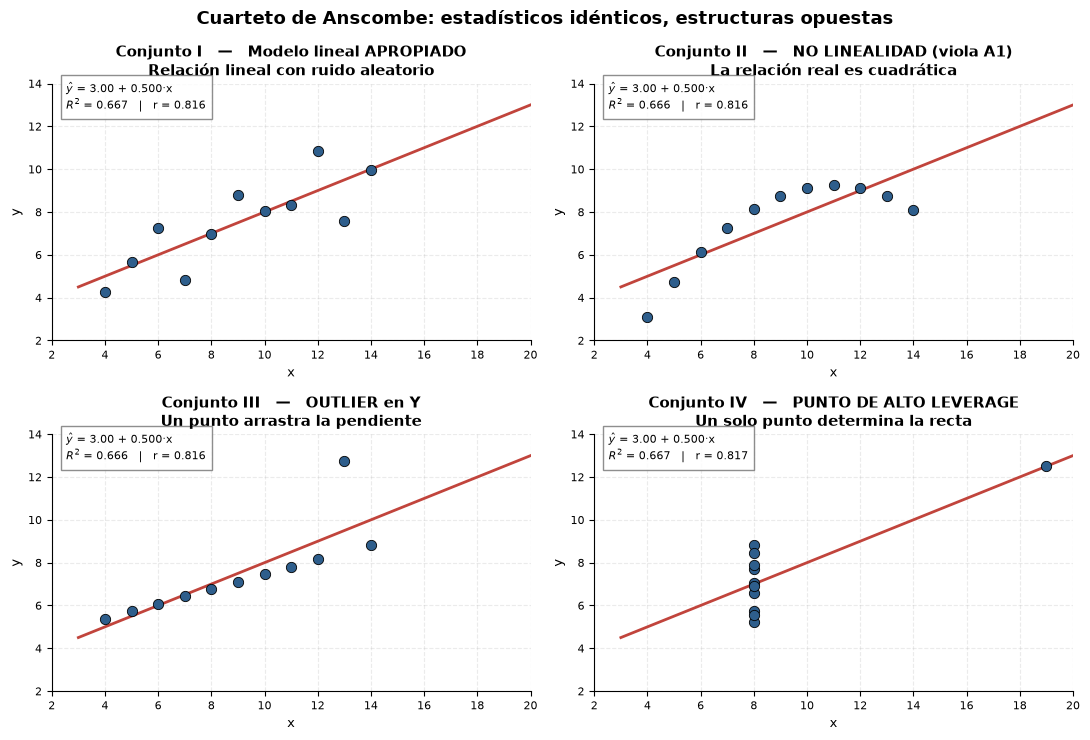

In [8]:
# Los mismos números, cuatro realidades distintas
# ==============================================================================
fig, axes = plt.subplots(2, 2, figsize=(11, 7.5))
diagnosticos = {
    'I'  : 'Modelo lineal APROPIADO\nRelación lineal con ruido aleatorio',
    'II' : 'NO LINEALIDAD (viola A1)\nLa relación real es cuadrática',
    'III': 'OUTLIER en Y\nUn punto arrastra la pendiente',
    'IV' : 'PUNTO DE ALTO LEVERAGE\nUn solo punto determina la recta',
}
for ax, (nombre, g) in zip(axes.flat, anscombe.groupby('dataset')):
    m  = smf.ols('y ~ x', data=g).fit()
    xg = np.linspace(3, 20, 50)
    ax.scatter(g.x, g.y, s=55, color=AZUL, edgecolors='black', lw=.6, zorder=3)
    ax.plot(xg, m.params['Intercept'] + m.params['x'] * xg, color=ROJO, lw=2)
    ax.set(title=f'Conjunto {nombre}   —   {diagnosticos[nombre]}', xlim=(2, 20), ylim=(2, 14),
           xlabel='x', ylabel='y')
    ax.text(.03, .90, f"$\\hat y$ = {m.params['Intercept']:.2f} + {m.params['x']:.3f}·x\n"
                      f"$R^2$ = {m.rsquared:.3f}   |   r = {pearsonr(g.x, g.y)[0]:.3f}",
            transform=ax.transAxes, fontsize=8,
            bbox=dict(fc='white', ec=GRIS, alpha=.85))
fig.suptitle('Cuarteto de Anscombe: estadísticos idénticos, estructuras opuestas')
fig.tight_layout()
plt.show()

### Lectura

Los cuatro conjuntos producen **exactamente el mismo `summary()`**. Si nuestro flujo de trabajo
consistiera en mirar $R^2$ y el p-valor de la pendiente, aprobaríamos los cuatro modelos por igual.

- **I**: el único donde el modelo lineal es apropiado.
- **II**: relación determinista **cuadrática**. El $R^2 = 0.666$ es engañoso: podríamos alcanzar
  $R^2 \approx 1$ con el término correcto. El gráfico de residuos mostraría una parábola perfecta.
- **III**: relación lineal perfecta salvo **un outlier** que desvía la recta. Sin ese punto,
  $R^2 = 1$.
- **IV**: todos los $x$ valen 8 salvo uno que vale 19. Ese único punto **determina completamente**
  la pendiente: es un caso de leverage $h_{ii}$ cercano a 1. Sin él, la pendiente no está siquiera
  definida.

> **Conclusión operativa:** el gráfico de residuos no es un adorno del informe. Es el instrumento
> principal de diagnóstico, y los tests formales son solo su confirmación cuantitativa.

## 1.4 Ejemplo gráfico: galería de patrones de residuos

El gráfico **residuos vs valores ajustados** es la herramienta más rentable del diagnóstico: en un
solo panel se ven violaciones de A1 (linealidad), A3 (homocedasticidad) y presencia de outliers.
Aprender a leerlo es aprender a reconocer cuatro *firmas* visuales.

Vamos a simular cada patrón con datos donde **conocemos la verdad**, para fijar la referencia
visual antes de enfrentarnos a datos reales.

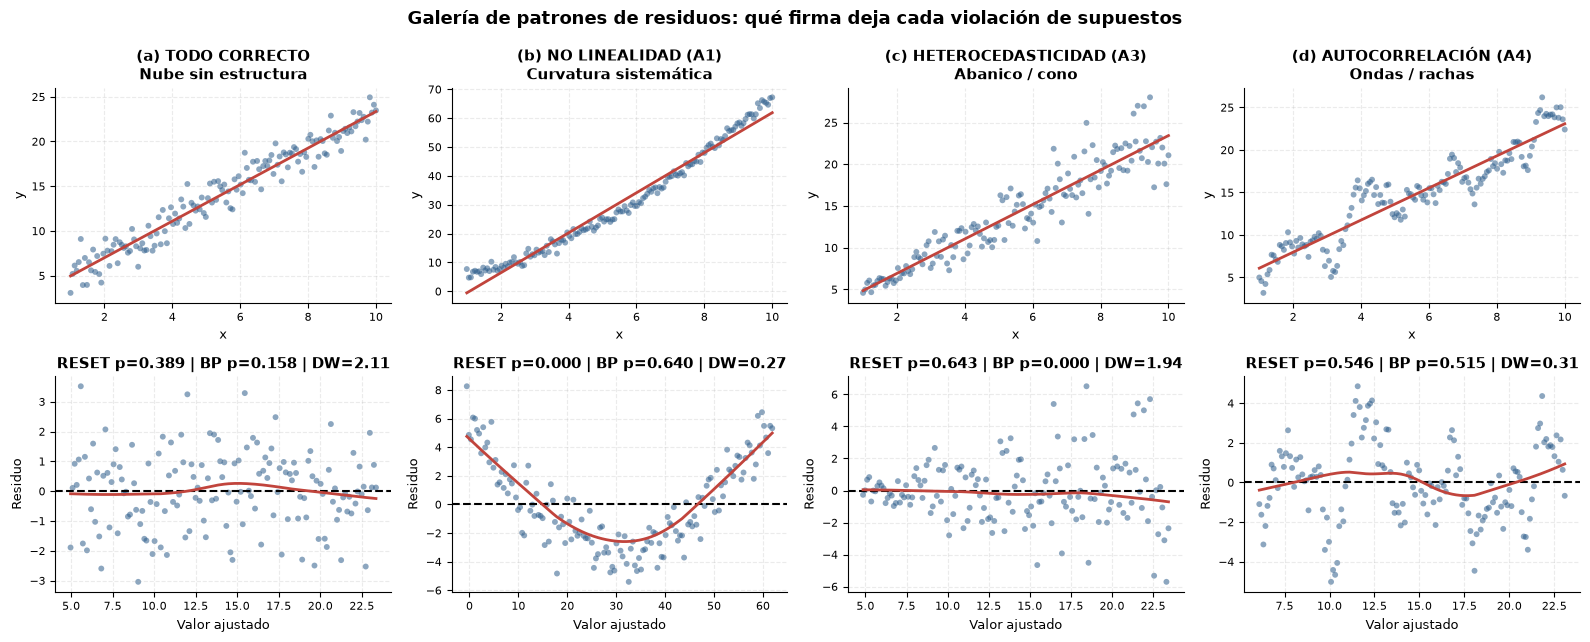

In [9]:
# Simulación de los cuatro escenarios canónicos
# ==============================================================================
n_sim = 150
x_sim = np.linspace(1, 10, n_sim)
sim = {}

# (a) Modelo correcto: residuos como "cielo estrellado" sin estructura
sim['(a) TODO CORRECTO\nNube sin estructura'] = 3 + 2*x_sim + rng.normal(0, 1.2, n_sim)

# (b) No linealidad: falta un término cuadrático  -> viola A1
sim['(b) NO LINEALIDAD (A1)\nCurvatura sistemática'] = 3 + 2*x_sim + 0.45*x_sim**2 + rng.normal(0, 1.2, n_sim)

# (c) Heterocedasticidad: varianza creciente con x  -> viola A3
sim['(c) HETEROCEDASTICIDAD (A3)\nAbanico / cono'] = 3 + 2*x_sim + rng.normal(0, 0.35*x_sim, n_sim)

# (d) Autocorrelación: errores con memoria AR(1)   -> viola A4
e_ar = np.zeros(n_sim)
for i in range(1, n_sim):
    e_ar[i] = 0.92 * e_ar[i-1] + rng.normal(0, 1.0)
sim['(d) AUTOCORRELACIÓN (A4)\nOndas / rachas'] = 3 + 2*x_sim + e_ar

fig, axes = plt.subplots(2, 4, figsize=(16, 6.5))
for j, (titulo, y_sim) in enumerate(sim.items()):
    df_sim = pd.DataFrame({'x': x_sim, 'y': y_sim})
    m      = smf.ols('y ~ x', data=df_sim).fit()

    # Fila superior: datos + recta ajustada
    axes[0, j].scatter(x_sim, y_sim, s=18, alpha=.55, color=AZUL, edgecolors='none')
    axes[0, j].plot(x_sim, m.fittedvalues, color=ROJO, lw=2)
    axes[0, j].set(title=titulo, xlabel='x', ylabel='y')

    # Fila inferior: residuos vs ajustados
    axes[1, j].scatter(m.fittedvalues, m.resid, s=18, alpha=.55, color=AZUL, edgecolors='none')
    axes[1, j].axhline(0, color='black', ls='--', lw=1.5)
    sl = sm.nonparametric.lowess(m.resid, m.fittedvalues, frac=.6)
    axes[1, j].plot(sl[:, 0], sl[:, 1], color=ROJO, lw=2)

    bp_p    = het_breuschpagan(m.resid, m.model.exog)[1]
    reset_p = linear_reset(m, power=2, test_type='fitted', use_f=True).pvalue
    dw      = durbin_watson(m.resid)
    axes[1, j].set(xlabel='Valor ajustado', ylabel='Residuo',
                   title=f'RESET p={reset_p:.3f} | BP p={bp_p:.3f} | DW={dw:.2f}')

fig.suptitle('Galería de patrones de residuos: qué firma deja cada violación de supuestos')
fig.tight_layout()
plt.show()

### Cómo leer cada firma

| Patrón visual | Violación | Test que lo detecta | Qué hacer |
|---|---|---|---|
| **Nube sin estructura** | ninguna | RESET y BP no significativos, DW ≈ 2 | Seguir adelante |
| **Curva (U o ∩)** | A1 linealidad | **RESET de Ramsey** significativo | Transformar X, añadir $X^2$, interacciones |
| **Abanico / cono** | A3 homocedasticidad | **Breusch-Pagan / White** significativos | Errores robustos HC3, WLS, transformar Y |
| **Ondas o rachas largas** | A4 independencia | **Durbin-Watson** lejos de 2, Breusch-Godfrey | Errores HAC, GLS, modelo de series temporales |

Observa los estadísticos impresos en la fila inferior. Cada test detecta con claridad **su**
problema: en (b) el RESET se dispara ($p < 0.001$); en (c) lo hace el Breusch-Pagan; en (d) el
Durbin-Watson se aleja de 2 (con $\rho = 0.92$ esperaríamos $DW \approx 2(1-\rho) \approx 0.16$).

Pero fíjate también en algo que rara vez se menciona: **en (b) el Durbin-Watson también se dispara**
($DW = 0.27$), aunque los errores de esa simulación son perfectamente independientes. La razón es
que los datos están ordenados por $x$, y una curvatura sistemática hace que residuos consecutivos
se parezcan entre sí. El DW no distingue entre «errores correlacionados» y «modelo mal especificado
sobre datos ordenados».

> ⚠️ **Los tests de diagnóstico no son selectivos.** Una violación puede activar varios tests a la
> vez, y un test puede activarse por una causa distinta de la que le da nombre. Por eso el
> diagnóstico se interpreta **en conjunto y jerárquicamente**: primero se resuelve la especificación
> (A1) y solo después se juzgan los demás supuestos, porque una mala especificación contamina todo
> lo demás. Veremos exactamente ese fenómeno en el Caso 2.

> **Detalle importante en (c):** aunque la varianza crece con $x$, la recta ajustada sigue siendo
> **insesgada** (pasa por el centro de la nube). Lo que está mal son los *errores estándar*: OLS
> pondera igual a las observaciones fiables (las de la izquierda) y a las ruidosas (las de la
> derecha), y por eso subestima la incertidumbre. Es exactamente lo que anticipaba la tabla de 1.2.

---
## 1.5 Marco de decisión: qué hacer cuando *(no si)* los supuestos fallan

Aquí está la diferencia entre un curso de estadística y la práctica real.

> **Con datos reales, algún supuesto va a fallar. Casi siempre.**
> Un modelo que pasa los seis chequeos limpiamente es la excepción, no la norma.

Si la regla fuese "si algún test sale significativo, descarto el modelo", no se publicaría casi
nada y no se tomaría casi ninguna decisión. La pregunta profesional no es *¿se cumplen los
supuestos?* sino:

> **¿Qué supuesto falla, cuánto importa para lo que quiero hacer, y qué hago al respecto?**

Las cuatro reglas siguientes son el núcleo de esta clase. Todo lo demás son herramientas para
aplicarlas.

---

### Regla 1 · El objetivo decide qué supuestos importan

El mismo fallo puede ser irrelevante o fatal según para qué uses el modelo.

| Si tu objetivo es… | Supuestos **críticos** | Supuestos que puedes tolerar |
|---|---|---|
| **Predecir** un valor puntual | A1 (linealidad) | A3, A4, A5, colinealidad: casi irrelevantes |
| **Predecir con intervalos** | A1, **A3**, **A5** | colinealidad |
| **Inferir** (¿cuánto vale β? ¿es ≠ 0?) | A1, A2, A3, A4 (+A5 si $n$ es pequeño) | colinealidad moderada |
| **Afirmar causalidad** | **A2 por encima de todo** | el resto es secundario si A2 falla |

*Ejemplo concreto:* un modelo heterocedástico usado para **predecir** ventas es perfectamente
utilizable —$\hat\beta$ sigue insesgado—. El mismo modelo usado para **decidir si la radio
funciona** requiere corregir los errores estándar antes de mirar un solo p-valor.

---

### Regla 2 · Jerarquía de gravedad: no todos los fallos son iguales

| | Supuestos | Por qué | Qué exige |
|---|---|---|---|
| 🔴 **BLOQUEANTE** | **A1** linealidad · **A2** exogeneidad · **A4** independencia | **Sesgan $\hat\beta$** o destruyen los errores estándar. Lo que estimas no es lo que crees estimar. | **Parar y corregir.** Todo lo que venga después es ruido. |
| 🟡 **CORREGIBLE** | **A3** heterocedasticidad · **A5** normalidad con $n$ pequeño · colinealidad alta · observaciones influyentes | $\hat\beta$ es válido; lo que está mal es **la medida de su incertidumbre**. | Aplicar la corrección (HC3, bootstrap, centrar, sensibilidad) y seguir. |
| 🟢 **TOLERABLE** | **A5** con $n \gtrsim 50$ · colinealidad moderada · heterocedasticidad si solo predices | El TLC o la irrelevancia para el objetivo lo neutralizan. | **Documentarlo y seguir.** No perder tiempo. |

> El error más común en la práctica no es ignorar los supuestos: es **tratarlos todos con la misma
> urgencia**. Se dedican horas a "arreglar" una no-normalidad inocua con $n = 500$ mientras se pasa
> por alto un RESET significativo que está sesgando todos los coeficientes.

---

### Regla 3 · El orden de trabajo no es negociable

$$\textbf{1. Especificación (A1)} \;\rightarrow\; \text{2. Independencia (A4)} \;\rightarrow\;
\text{3. Varianza (A3)} \;\rightarrow\; \text{4. Normalidad (A5)} \;\rightarrow\; \text{5. Influencia}$$

**Por qué este orden y no otro:** una mala especificación **fabrica** los otros síntomas. Si al
modelo le falta una interacción, los errores del modelo dejan de ser aleatorios y se vuelven
sistemáticos, lo que produce residuos asimétricos (falsa no-normalidad) y de varianza variable
(falsa heterocedasticidad). Corriges los síntomas, el problema real sigue ahí —y los coeficientes
siguen sesgados.

Lo veremos literalmente en el Caso 2: un modelo con tres supuestos "rotos" resulta tener **una sola
causa**, y al corregirla los tres se arreglan a la vez.

---

### Regla 4 · Cuándo dejar de insistir y cambiar de técnica

Iterar sobre la especificación tiene rendimientos decrecientes y riesgo de sobreajustar a la
muestra. Criterios de parada:

| Señal | Interpretación | Qué hacer |
|---|---|---|
| Tras 2–3 iteraciones el RESET sigue significativo | La relación no es linealizable con transformaciones simples | GAM, splines, árboles/boosting |
| $Y$ es un conteo, una proporción o está acotada | El modelo lineal es la herramienta equivocada de raíz | GLM (Poisson, binomial, Gamma) |
| La varianza depende estructuralmente de la media | Es una propiedad del proceso, no un defecto a parchear | GLM con la familia adecuada |
| Los datos tienen grupos, jerarquías o repeticiones | A4 falla por diseño | Modelos mixtos, errores agrupados |
| La mejora en validación cruzada es < 5% | Estás ajustando ruido | **Parar.** Quedarse con el modelo más simple |

> **Y la regla que no se dice en voz alta:** a veces el resultado correcto es *"con estos datos no
> se puede responder a esta pregunta"*. Lo vamos a ver en el Caso 1, donde el modelo es
> estadísticamente impecable y aun así inútil para lo que pedía el cliente.

---

### El protocolo mínimo

Esto es todo lo que hay que ejecutar de forma rutinaria. Seis salidas, no sesenta:

| Paso | Qué se hace | Salida |
|---|---|---|
| **1** | Explorar la relación sin imponerla | Dispersión + LOWESS |
| **2** | Ajustar y leer el modelo | `summary()` |
| **3** | Mirar los residuos | `panel_diagnostico()` |
| **4** | Chequear supuestos según el objetivo | `diagnostico(modelo, objetivo=...)` |
| **5** | Corregir lo bloqueante y repetir 2–4 | — |
| **6** | Validar fuera de muestra | Validación cruzada / test |

Un test por supuesto es suficiente para decidir. La batería exhaustiva
(`diagnostico_completo()`) queda como ampliación, para cuando el chequeo mínimo deja dudas o hay
que documentar formalmente un modelo.

> 📌 **Nota para la sesión:** las secciones marcadas con **🔍** son ampliaciones. Se pueden saltar
> sin romper el hilo; están ahí para responder al alumno que pregunta *"¿y por qué?"*.

---
---
# Caso aplicado: bateos → runs

## 2.1 Contexto y datos

> Un analista deportivo quiere saber si existe relación entre el número de veces que batean los
> jugadores de un equipo de béisbol (**bateos**) y el número de carreras que consigue (**runs**).
> Si la relación existe y se puede modelar, podría anticipar el resultado de un partido.

Antes de escribir una línea de código, conviene fijar el marco:

| Elemento | En este caso |
|---|---|
| Unidad de observación | El equipo (una temporada) |
| Variable respuesta $Y$ | `runs` (carreras conseguidas) |
| Predictor $X$ | `bateos` (turnos al bate) |
| Tamaño muestral | $n = 30$ equipos |
| Naturaleza del estudio | **Observacional**, no experimental |
| Objetivo declarado | Predictivo *y* explicativo |

**Dos advertencias que condicionan todo lo que sigue:**

1. **$n = 30$ es una muestra pequeña.** Con 30 observaciones, el supuesto de normalidad (A5) sí
   importa, la potencia estadística es baja y cualquier partición train/test será extremadamente
   inestable. Lo veremos cuantificado en §2.9.
2. **Es un estudio observacional.** Aunque encontremos una relación fuerte, no podremos afirmar
   que batear más *causa* más carreras: ambas variables podrían estar impulsadas por la calidad
   general del equipo (un confusor no medido). El supuesto A2 (exogeneidad) no es verificable con
   estos datos.

In [10]:
# Datos del Caso 1: 30 equipos de béisbol
# ==============================================================================
equipos = ["Texas","Boston","Detroit","Kansas","St.","New_S.","New_Y.",
           "Milwaukee","Colorado","Houston","Baltimore","Los_An.","Chicago",
           "Cincinnati","Los_P.","Philadelphia","Chicago","Cleveland","Arizona",
           "Toronto","Minnesota","Florida","Pittsburgh","Oakland","Tampa",
           "Atlanta","Washington","San.F","San.I","Seattle"]
bateos = [5659,  5710, 5563, 5672, 5532, 5600, 5518, 5447, 5544, 5598,
          5585, 5436, 5549, 5612, 5513, 5579, 5502, 5509, 5421, 5559,
          5487, 5508, 5421, 5452, 5436, 5528, 5441, 5486, 5417, 5421]

runs = [855, 875, 787, 730, 762, 718, 867, 721, 735, 615, 708, 644, 654, 735,
        667, 713, 654, 704, 731, 743, 619, 625, 610, 645, 707, 641, 624, 570,
        593, 556]

beisbol = pd.DataFrame({'equipos': equipos, 'bateos': bateos, 'runs': runs})
beisbol.head(3)

,equipos,bateos,runs
0,Texas,5659,855
1,Boston,5710,875
2,Detroit,5563,787


In [11]:
# Estructura y calidad del dataset
# ==============================================================================
print(f"Dimensiones: {beisbol.shape[0]} filas × {beisbol.shape[1]} columnas\n")
print("Tipos y valores ausentes:")
print(pd.DataFrame({'tipo': beisbol.dtypes, 'nulos': beisbol.isna().sum(),
                    'únicos': beisbol.nunique()}))
print("\nEstadísticos descriptivos:")
display(beisbol[['bateos', 'runs']].describe().T.assign(
    CV=lambda d: d['std'] / d['mean'],
    asimetría=[stats.skew(beisbol.bateos), stats.skew(beisbol.runs)],
    curtosis=[stats.kurtosis(beisbol.bateos), stats.kurtosis(beisbol.runs)],
))
beisbol.head()

Dimensiones: 30 filas × 3 columnas

Tipos y valores ausentes:
          tipo  nulos  únicos
equipos    str      0      29
bateos   int64      0      27
runs     int64      0      28

Estadísticos descriptivos:


,count,mean,std,min,25%,50%,75%,max,CV,asimetría,curtosis
bateos,30.0000,"5,523.5000",79.8731,"5,417.0000","5,448.2500","5,515.5000","5,575.0000","5,710.0000",0.0145,0.4864,-0.4795
runs,30.0000,693.6000,82.4791,556.0000,629.0000,705.5000,734.0000,875.0000,0.1189,0.5471,-0.1767


,equipos,bateos,runs
0,Texas,5659,855
1,Boston,5710,875
2,Detroit,5563,787
3,Kansas,5672,730
4,St.,5532,762


## 2.2 Análisis exploratorio

El EDA en regresión no es "mirar los datos por mirar": tiene tres objetivos concretos.

1. **Verificar que la relación tiene forma lineal** (supuesto A1) *antes* de imponerla.
2. **Detectar observaciones extremas** que puedan dominar el ajuste (Anscombe III y IV).
3. **Conocer el rango de $X$**, que delimita la región donde el modelo será válido: predecir fuera
   de ese rango es **extrapolar**, y ahí el modelo no tiene ningún respaldo empírico.

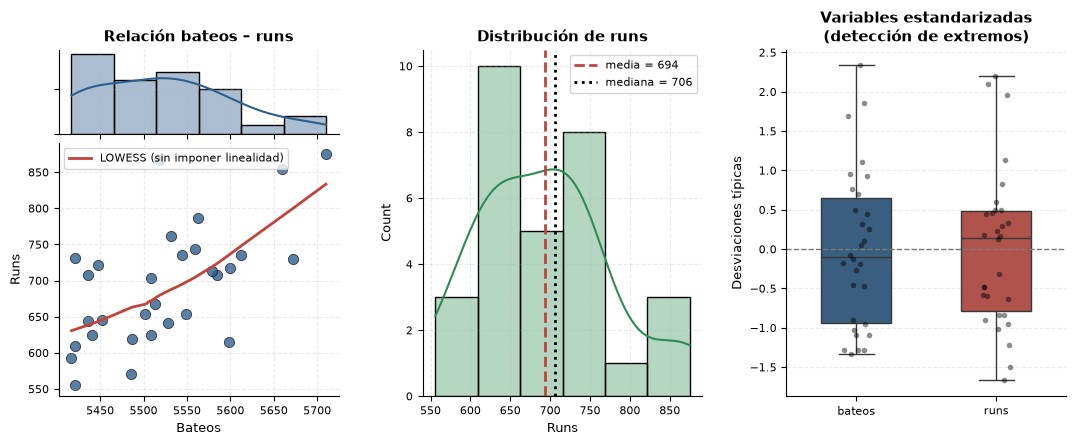

Rango de validez del modelo (dominio observado de X): [5417, 5710] bateos
Amplitud del rango: 293 bateos (5.3% de la media)


In [12]:
# Panel exploratorio
# ==============================================================================
fig = plt.figure(figsize=(13, 4.5))
gs  = fig.add_gridspec(2, 3, height_ratios=[1, 3], hspace=.05, wspace=.3)

# --- Dispersión con marginales -------------------------------------------
ax_sc  = fig.add_subplot(gs[1, 0])
ax_top = fig.add_subplot(gs[0, 0], sharex=ax_sc)
ax_sc.scatter(beisbol.bateos, beisbol.runs, s=55, color=AZUL, edgecolors='black', lw=.5, alpha=.8)
sl = sm.nonparametric.lowess(beisbol.runs, beisbol.bateos, frac=.8)
ax_sc.plot(sl[:, 0], sl[:, 1], color=ROJO, lw=2, label='LOWESS (sin imponer linealidad)')
ax_sc.legend(loc='upper left')
ax_sc.set(xlabel='Bateos', ylabel='Runs', title='')
sns.histplot(x=beisbol.bateos, ax=ax_top, color=AZUL, alpha=.4, kde=True)
ax_top.set(ylabel='', xlabel='', title='Relación bateos – runs')
ax_top.tick_params(labelbottom=False, labelleft=False)

# --- Distribución de la respuesta ----------------------------------------
ax2 = fig.add_subplot(gs[:, 1])
sns.histplot(beisbol.runs, kde=True, color=VERDE, alpha=.35, ax=ax2)
ax2.axvline(beisbol.runs.mean(), color=ROJO, ls='--', lw=2, label=f'media = {beisbol.runs.mean():.0f}')
ax2.axvline(beisbol.runs.median(), color='black', ls=':', lw=2, label=f'mediana = {beisbol.runs.median():.0f}')
ax2.legend(); ax2.set(title='Distribución de runs', xlabel='Runs')

# --- Boxplots estandarizados ---------------------------------------------
ax3 = fig.add_subplot(gs[:, 2])
z = (beisbol[['bateos', 'runs']] - beisbol[['bateos', 'runs']].mean()) / beisbol[['bateos', 'runs']].std()
sns.boxplot(data=z, ax=ax3, width=.5)
sns.stripplot(data=z, ax=ax3, color='black', alpha=.45, size=4)
ax3.set(title='Variables estandarizadas\n(detección de extremos)', ylabel='Desviaciones típicas')
ax3.axhline(0, color=GRIS, ls='--', lw=1)

plt.show()

print(f"Rango de validez del modelo (dominio observado de X): "
      f"[{beisbol.bateos.min()}, {beisbol.bateos.max()}] bateos")
print(f"Amplitud del rango: {beisbol.bateos.max() - beisbol.bateos.min()} bateos "
      f"({100*(beisbol.bateos.max()-beisbol.bateos.min())/beisbol.bateos.mean():.1f}% de la media)")

### Lectura del EDA

- La curva **LOWESS** (suavizado local que *no* impone linealidad) es aproximadamente recta: no hay
  evidencia visual contra A1.
- El rango de `bateos` es estrecho (≈ 5% de la media). Esto tiene una consecuencia estadística
  concreta: la varianza del estimador de la pendiente es
  $\text{Var}(\hat\beta_1) = \sigma^2 / \sum(x_i - \bar x)^2$, de modo que **cuanto menos varía $X$,
  más imprecisa es la pendiente**. Un rango estrecho es una de las razones por las que veremos un
  error estándar relativamente grande.
- No hay valores ausentes ni imposibles.

## 2.3 Correlación: cuantificar la asociación *y su incertidumbre*

El coeficiente de correlación de Pearson mide la asociación **lineal**:

$$r = \frac{\sum (x_i-\bar x)(y_i-\bar y)}{\sqrt{\sum (x_i-\bar x)^2}\sqrt{\sum (y_i-\bar y)^2}} \in [-1, 1]$$

Reportar solo $r$ y su p-valor es insuficiente. Con $n=30$, $r$ es un estimador **muy variable**.
Vamos a acompañarlo de:

- **Spearman** ($\rho$): correlación de rangos. Si difiere mucho de Pearson, hay no linealidad
  monótona o outliers influyentes.
- **Intervalo de confianza de Fisher**: se basa en la transformación
  $z = \tfrac12\ln\frac{1+r}{1-r} \sim N\!\left(\tfrac12\ln\frac{1+\rho}{1-\rho},\; \tfrac{1}{n-3}\right)$,
  que normaliza la distribución de $r$.
- **Bootstrap**: remuestreo no paramétrico, sin supuestos distribucionales.

Pearson  r = 0.6106   p-valor = 0.000339
Spearman ρ = 0.6040   p-valor = 0.000409

IC 95% (Fisher)    : [0.321, 0.796]
IC 95% (bootstrap) : [0.299, 0.817]
Error estándar bootstrap de r: 0.1347


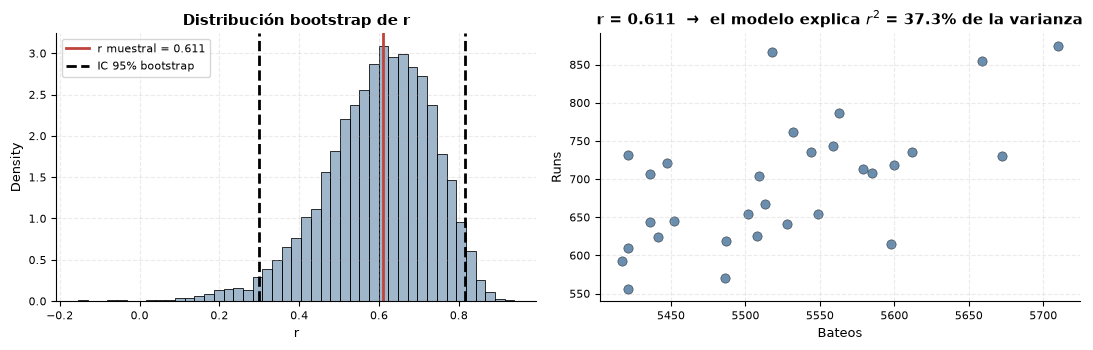

In [13]:
# Correlación con medida de incertidumbre
# ==============================================================================
r_p = pearsonr(beisbol.bateos, beisbol.runs)
r_s = spearmanr(beisbol.bateos, beisbol.runs)

# IC analítico (transformación z de Fisher)
ic_fisher = r_p.confidence_interval(confidence_level=0.95)

# IC por bootstrap no paramétrico (5.000 remuestreos)
rng_boot = np.random.default_rng(SEED)
r_boot = np.array([
    pearsonr(*beisbol.sample(len(beisbol), replace=True,
                           random_state=int(rng_boot.integers(1e9)))[['bateos', 'runs']].values.T).statistic
    for _ in range(5000)
])
ic_boot = np.percentile(r_boot, [2.5, 97.5])

print(f"Pearson  r = {r_p.statistic:.4f}   p-valor = {r_p.pvalue:.6f}")
print(f"Spearman ρ = {r_s.statistic:.4f}   p-valor = {r_s.pvalue:.6f}")
print(f"\nIC 95% (Fisher)    : [{ic_fisher.low:.3f}, {ic_fisher.high:.3f}]")
print(f"IC 95% (bootstrap) : [{ic_boot[0]:.3f}, {ic_boot[1]:.3f}]")
print(f"Error estándar bootstrap de r: {r_boot.std():.4f}")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
sns.histplot(r_boot, bins=45, color=AZUL, alpha=.45, ax=ax[0], stat='density')
for v, c, l in [(r_p.statistic, ROJO, f'r muestral = {r_p.statistic:.3f}'),
                (ic_boot[0], 'black', 'IC 95% bootstrap'), (ic_boot[1], 'black', None)]:
    ax[0].axvline(v, color=c, ls='--' if c == 'black' else '-', lw=2, label=l)
ax[0].legend(); ax[0].set(title='Distribución bootstrap de r', xlabel='r')

ax[1].scatter(beisbol.bateos, beisbol.runs, s=45, color=AZUL, alpha=.7, edgecolors='black', lw=.4)
ax[1].set(title=f'r = {r_p.statistic:.3f}  →  el modelo explica $r^2$ = {r_p.statistic**2:.1%} de la varianza',
          xlabel='Bateos', ylabel='Runs')
plt.tight_layout(); plt.show()

### Interpretación

- Pearson ($r = 0.611$) y Spearman ($\rho = 0.604$) casi coinciden: no hay señales de no linealidad
  monótona ni de un outlier dominante que infle la asociación.
- El p-valor es 0.00034: rechazamos $H_0: \rho = 0$.
- **Pero mira el intervalo de confianza: $[0.32,\; 0.80]$.** Ese es el mensaje importante.
  La asociación poblacional podría ser moderada-débil (0.32) o muy fuerte (0.80). Con $n=30$ no
  tenemos resolución para distinguirlo.
- Los ICs de Fisher y bootstrap prácticamente coinciden, lo que sugiere que la aproximación
  analítica es razonable aquí.

> **El p-valor responde a "¿hay señal?"; el intervalo de confianza responde a "¿cuánta señal, y con
> qué precisión la conozco?".** La segunda pregunta es casi siempre la relevante para decidir.
> Reportar únicamente "p < 0.05" es tirar el 90% de la información del análisis.

Y recuerda Anscombe: $r$ solo resume la parte lineal. Un $r$ alto no garantiza linealidad, y un
$r$ bajo no descarta una relación fuerte no lineal.

---

## 2.4 Ajuste del modelo por OLS

### Una decisión metodológica previa: ¿train/test o muestra completa?

El notebook de partida dividía los 30 equipos en 24 de entrenamiento y 6 de test, y hacía la
inferencia sobre los 24. Conviene separar dos objetivos que requieren estrategias distintas:

| Objetivo | Pregunta | Estrategia correcta |
|---|---|---|
| **Inferencial / explicativo** | ¿Cuánto vale $\beta_1$ en la población? ¿Es distinto de 0? | Usar **toda** la muestra. Tirar el 20% de los datos solo aumenta el error estándar y reduce la potencia. |
| **Predictivo** | ¿Cuánto me equivocaré con un equipo nuevo? | Estimar el error **fuera de muestra** (validación cruzada; train/test si $n$ es grande). |

Vamos a hacer **las dos cosas, cada una con su método**: la inferencia y el diagnóstico sobre los
30 equipos (§2.4–2.8), y la evaluación predictiva por validación cruzada (§2.9).

### Sintaxis de fórmula

Usaremos la API de fórmulas de `statsmodels` (`smf.ols`), equivalente a la de R. Es preferible a
pasar matrices porque:

- gestiona automáticamente el intercepto (nada de `add_constant` manual),
- conserva los **nombres** de las variables en toda la salida,
- permite escribir transformaciones e interacciones directamente en la fórmula
  (`np.log(x)`, `x*z`, `I(x**2)`),
- evita la clase de error que veremos en la Parte 4: mezclar matrices y DataFrames y perder el
  control de qué columnas entran en el modelo.

In [14]:
# Ajuste OLS sobre la muestra completa (n = 30)
# ==============================================================================
modelo_simple = smf.ols(formula='runs ~ bateos', data=beisbol).fit()
print(modelo_simple.summary())

                            OLS Regression Results                            
Dep. Variable:                   runs   R-squared:                       0.373
Model:                            OLS   Adj. R-squared:                  0.350
Method:                 Least Squares   F-statistic:                     16.65
Date:                Tue, 04 Aug 2026   Prob (F-statistic):           0.000339
Time:                        19:35:02   Log-Likelihood:                -167.44
No. Observations:                  30   AIC:                             338.9
Df Residuals:                      28   BIC:                             341.7
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept  -2789.2429    853.696     -3.267      0.0

### Anatomía del `summary()`: qué significa cada número

Esta tabla es el instrumento de trabajo del resto de la clase. Vamos campo por campo.

#### Bloque 1 — Bondad de ajuste global

| Campo | Valor | Qué es | Cómo se lee |
|---|---|---|---|
| `R-squared` | 0.373 | $R^2 = 1 - \dfrac{SSE}{SST} = \dfrac{SSR}{SST}$ | El modelo explica el **37.3%** de la variabilidad de `runs`. |
| `Adj. R-squared` | 0.350 | $R^2_{adj} = 1-(1-R^2)\dfrac{n-1}{n-k-1}$ | Penaliza por número de predictores. **Siempre** usar este para comparar modelos con distinto $k$. |
| `F-statistic` | 16.65 | Contraste global $H_0:\beta_1=\dots=\beta_k=0$ | El modelo, en conjunto, explica más de lo esperable por azar. |
| `Prob (F-statistic)` | 0.000339 | p-valor del test F | Rechazamos $H_0$ global. |
| `Log-Likelihood` / `AIC` / `BIC` | −167.4 / 338.9 / 341.7 | Verosimilitud y criterios de información | Solo tienen sentido **comparando** modelos sobre los mismos datos. Menor AIC/BIC = mejor. |

> **Nota sobre $R^2$.** No mide si el modelo es correcto, ni si es útil, ni si es causal. Mide
> qué fracción de la varianza reproduce el ajuste **en la muestra usada para ajustarlo**. Añadir
> cualquier variable —incluso ruido puro— nunca reduce $R^2$. Por eso, en presencia de varios
> predictores, $R^2$ sin ajustar es una métrica engañosa.

#### Bloque 2 — Coeficientes

```
                 coef    std err          t      P>|t|      [0.025      0.975]
Intercept  -2789.2429    853.696     -3.267      0.003   -4537.959   -1040.526
bateos         0.6305      0.155      4.080      0.000       0.314       0.947
```

- **`coef`**: la estimación puntual $\hat\beta_j$.
- **`std err`**: $\widehat{SE}(\hat\beta_j) = \sqrt{\hat\sigma^2\left[(\mathbf X^\top\mathbf X)^{-1}\right]_{jj}}$.
  **Este es el número que se corrompe cuando fallan A3 o A4.**
- **`t`**: estadístico del contraste $H_0: \beta_j = 0$, es decir $t = \hat\beta_j / SE(\hat\beta_j)$,
  que sigue una $t_{n-k-1}$ **bajo A5** (o asintóticamente por el TLC).
- **`P>|t|`**: p-valor bilateral.
- **`[0.025, 0.975]`**: intervalo de confianza al 95%, $\hat\beta_j \pm t_{0.975,\,n-k-1}\cdot SE$.

#### Bloque 3 — Diagnóstico incorporado (¡el que nadie lee!)

| Campo | Valor | Qué contrasta |
|---|---|---|
| `Omnibus` / `Prob(Omnibus)` | 2.579 / 0.275 | Test de D'Agostino-Pearson: **normalidad** de los residuos |
| `Skew` | 0.544 | Asimetría de los residuos (0 en una normal) |
| `Kurtosis` | 3.252 | Curtosis (3 en una normal) |
| `Jarque-Bera` / `Prob(JB)` | 1.559 / 0.459 | Otro test de **normalidad**, basado en asimetría y curtosis |
| `Durbin-Watson` | 1.524 | **Autocorrelación** de orden 1 (≈2 = ausencia) |
| `Cond. No.` | 3.89e+05 | Número de condición: colinealidad / **problemas de escala** |

En este modelo, ambos tests de normalidad son **no significativos** ($p = 0.275$ y $p = 0.459$):
buena señal, especialmente relevante con $n = 30$.

> **Sobre el `Cond. No.` de 389.000.** Statsmodels avisa de posible multicolinealidad, pero aquí
> solo hay un predictor: no puede haber colinealidad. El número de condición es alto simplemente
> porque `bateos` toma valores en torno a 5.500 mientras la columna del intercepto son unos.
> Es un problema de **escala**, no de colinealidad. Se disuelve al centrar la variable, y no afecta
> a la validez del ajuste. Es un ejemplo perfecto de advertencia automática que hay que saber leer
> en contexto en lugar de obedecer ciegamente.

In [15]:
# El número de condición es un problema de escala, no de colinealidad
# ==============================================================================
beisbol_c = beisbol.assign(bateos_c=beisbol.bateos - beisbol.bateos.mean())
modelo_centrado = smf.ols('runs ~ bateos_c', data=beisbol_c).fit()

comparacion = pd.DataFrame({
    'sin centrar': [modelo_simple.condition_number, modelo_simple.params['bateos'],
                    modelo_simple.bse['bateos'], modelo_simple.rsquared, modelo_simple.params['Intercept']],
    'centrado'   : [modelo_centrado.condition_number, modelo_centrado.params['bateos_c'],
                    modelo_centrado.bse['bateos_c'], modelo_centrado.rsquared, modelo_centrado.params['Intercept']],
}, index=['Número de condición', 'Pendiente', 'SE(pendiente)', 'R²', 'Intercepto'])
display(comparacion)

print("La pendiente, su error estándar y el R² son IDÉNTICOS.")
print("Solo cambian el número de condición y el intercepto, que ahora sí es interpretable:")
print(f"  runs esperados para un equipo con bateos promedio ({beisbol.bateos.mean():.0f}) = "
      f"{modelo_centrado.params['Intercept']:.1f}")

,sin centrar,centrado
Número de condición,"388,577.6119",78.5306
Pendiente,0.6305,0.6305
SE(pendiente),0.1545,0.1545
R²,0.3729,0.3729
Intercepto,"-2,789.2429",693.6000


La pendiente, su error estándar y el R² son IDÉNTICOS.
Solo cambian el número de condición y el intercepto, que ahora sí es interpretable:
  runs esperados para un equipo con bateos promedio (5524) = 693.6


## 2.5 Descomposición de la varianza y tabla ANOVA

Toda la lógica del test F descansa en una identidad geométrica (consecuencia del Teorema de
Pitágoras aplicado a la proyección ortogonal):

$$\underbrace{\sum_i (y_i-\bar y)^2}_{SST\;\text{(total)}} \;=\;
\underbrace{\sum_i (\hat y_i-\bar y)^2}_{SSR\;\text{(explicada por el modelo)}} \;+\;
\underbrace{\sum_i (y_i-\hat y_i)^2}_{SSE\;\text{(residual)}}$$

De ahí salen directamente:

$$R^2 = \frac{SSR}{SST}, \qquad
\hat\sigma^2 = \frac{SSE}{n-k-1} \;(\text{el } MSE), \qquad
F = \frac{SSR/k}{SSE/(n-k-1)} = \frac{MSR}{MSE}$$

El estadístico $F$ compara la varianza que el modelo **explica** por parámetro con la varianza que
**no** explica. Si el modelo no sirve, ambas son parecidas y $F \approx 1$.

In [16]:
# Tabla ANOVA de la regresión
# ==============================================================================
tabla_anova = anova_lm(modelo_simple, typ=1)
display(tabla_anova)

SSR = modelo_simple.ess            # explained sum of squares
SSE = modelo_simple.ssr            # sum of squared residuals (nomenclatura de statsmodels)
SST = modelo_simple.centered_tss
n_obs, k = int(modelo_simple.nobs), int(modelo_simple.df_model)

print(f"SST (total)     = {SST:>12,.1f}")
print(f"SSR (explicada) = {SSR:>12,.1f}   ({SSR/SST:.1%} del total)")
print(f"SSE (residual)  = {SSE:>12,.1f}   ({SSE/SST:.1%} del total)")
print(f"Comprobación SSR + SSE = {SSR + SSE:,.1f}  ==  SST = {SST:,.1f}")
print(f"\nσ̂ (error típico residual) = √(SSE/(n-k-1)) = {np.sqrt(modelo_simple.mse_resid):.2f} runs")

,df,sum_sq,mean_sq,F,PR(>F)
bateos,1.0000,"73,559.3316","73,559.3316",16.6475,0.0003
Residual,28.0000,"123,721.8684","4,418.6382",NaN,NaN


SST (total)     =    197,281.2
SSR (explicada) =     73,559.3   (37.3% del total)
SSE (residual)  =    123,721.9   (62.7% del total)
Comprobación SSR + SSE = 197,281.2  ==  SST = 197,281.2

σ̂ (error típico residual) = √(SSE/(n-k-1)) = 66.47 runs


---

## 2.6 Inferencia sobre los coeficientes

Un coeficiente sin intervalo de confianza es una estimación puntual sin medida de incertidumbre:
casi nunca es lo que hay que reportar.

$$\hat\beta_j \pm t_{1-\alpha/2,\;n-k-1}\cdot \widehat{SE}(\hat\beta_j)$$

In [17]:
# Intervalos de confianza al 95% y al 99%
# ==============================================================================
ic95 = modelo_simple.conf_int(alpha=0.05).rename(columns={0: 'IC95 inf', 1: 'IC95 sup'})
ic99 = modelo_simple.conf_int(alpha=0.01).rename(columns={0: 'IC99 inf', 1: 'IC99 sup'})

tabla_coef = pd.concat([
    modelo_simple.params.rename('coef'),
    modelo_simple.bse.rename('std err'),
    modelo_simple.tvalues.rename('t'),
    modelo_simple.pvalues.rename('p-valor'),
    ic95, ic99,
], axis=1)
display(tabla_coef.style.format({'coef': '{:,.4f}', 'std err': '{:,.4f}', 't': '{:.3f}',
                                 'p-valor': '{:.5f}', 'IC95 inf': '{:,.3f}', 'IC95 sup': '{:,.3f}',
                                 'IC99 inf': '{:,.3f}', 'IC99 sup': '{:,.3f}'}))

b1, se1 = modelo_simple.params['bateos'], modelo_simple.bse['bateos']
gl = int(modelo_simple.df_resid)
print(f"\nGrados de libertad residuales: n - k - 1 = {n_obs} - {k} - 1 = {gl}")
print(f"Valor crítico t(0.975, {gl}) = {stats.t.ppf(0.975, gl):.4f}")
print(f"Reconstrucción manual del IC95 de la pendiente: "
      f"{b1:.4f} ± {stats.t.ppf(0.975, gl):.4f} × {se1:.4f} = "
      f"[{b1 - stats.t.ppf(0.975, gl)*se1:.4f}, {b1 + stats.t.ppf(0.975, gl)*se1:.4f}]")

,coef,std err,t,p-valor,IC95 inf,IC95 sup,IC99 inf,IC99 sup
Intercept,"-2,789.2429",853.6957,-3.267,0.00287,"-4,537.959","-1,040.526","-5,148.228",-430.258
bateos,0.6305,0.1545,4.080,0.00034,0.314,0.947,0.204,1.058



Grados de libertad residuales: n - k - 1 = 30 - 1 - 1 = 28
Valor crítico t(0.975, 28) = 2.0484
Reconstrucción manual del IC95 de la pendiente: 0.6305 ± 2.0484 × 0.1545 = [0.3140, 0.9471]


### Interpretación rigurosa

**Pendiente ($\hat\beta_1 = 0.6305$).** Por cada bateo adicional, el número esperado de runs
aumenta en promedio 0.63, *manteniendo todo lo demás constante* y **dentro del rango observado**
de bateos. Su IC 95% es $[0.314,\ 0.947]$: los datos son compatibles con un efecto de 0.31 o con
uno tres veces mayor. Formulado en unidades interpretables: 100 bateos adicionales se asocian con
entre **31 y 95 runs** más.

**Intercepto ($\hat\beta_0 = -2789.2$).** Es el valor esperado de `runs` cuando `bateos = 0`.
Como el mínimo observado es 5.417 bateos, ese punto está a más de 5.000 unidades del rango de
datos: el intercepto es **matemáticamente necesario pero carece de interpretación sustantiva**.
Un equipo con 0 bateos no puede hacer −2.789 carreras. Por eso, en el modelo centrado de §2.4 el
intercepto sí era interpretable (runs esperados de un equipo promedio).

> ⚠️ **Extrapolación.** El modelo solo tiene respaldo empírico en $[5417,\ 5710]$ bateos. Fuera de
> ese intervalo, la recta es una *conjetura*, no una predicción. Y nada en la salida de
> `statsmodels` te avisará de que estás extrapolando.

**El p-valor, con precisión.** $p = 0.00034$ significa: *si en la población $\beta_1$ fuese
exactamente 0, la probabilidad de observar un $\hat\beta_1$ tan alejado de 0 como el nuestro (o
más) sería del 0.034%.* **No** significa que la probabilidad de que $H_0$ sea cierta sea 0.034%,
ni que el efecto sea grande, ni que sea importante en la práctica.

---

## 2.7 Intervalo de confianza vs intervalo de predicción

Esta distinción se confunde constantemente y tiene consecuencias prácticas enormes. Son dos
preguntas diferentes:

| | Pregunta | Fórmula del error estándar |
|---|---|---|
| **IC de la media** | ¿Dónde está el `runs` **promedio** de todos los equipos con $x_0$ bateos? | $\widehat{SE}_{\text{media}} = \hat\sigma\sqrt{\dfrac{1}{n} + \dfrac{(x_0-\bar x)^2}{\sum(x_i-\bar x)^2}}$ |
| **Intervalo de predicción** | ¿Dónde caerá el `runs` de **un equipo concreto** con $x_0$ bateos? | $\widehat{SE}_{\text{pred}} = \hat\sigma\sqrt{1 + \dfrac{1}{n} + \dfrac{(x_0-\bar x)^2}{\sum(x_i-\bar x)^2}}$ |

La diferencia es ese **"1 +"**. Al predecir una observación individual arrastramos dos fuentes de
incertidumbre:

1. la de no conocer la recta verdadera (**error de estimación**), que $\to 0$ cuando $n \to \infty$;
2. la variabilidad intrínseca del fenómeno alrededor de la recta ($\sigma^2$, el **error
   irreducible**), que **no desaparece nunca**, por muchos datos que tengamos.

Nota también el término $(x_0 - \bar x)^2$: ambos intervalos se **ensanchan** al alejarnos del
centro de los datos. Esa es la forma matemática de la penalización por extrapolar.

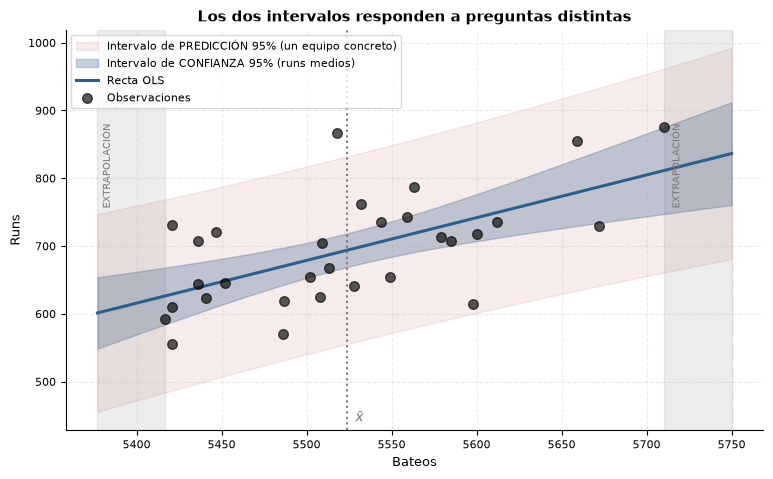

,bateos,mean,mean_ci_lower,mean_ci_upper,obs_ci_lower,obs_ci_upper,ancho IC media,ancho IC predicc.,ratio
0,5450,647.3000,613.2000,681.3000,506.9000,787.6000,68.1000,280.7000,4.1000
1,5523,693.3000,668.4000,718.1000,554.9000,831.7000,49.7000,276.8000,5.6000
2,5700,804.9000,743.7000,866.0000,655.6000,954.2000,122.3000,298.5000,2.4000


In [18]:
# Bandas de confianza y de predicción
# ==============================================================================
grid   = pd.DataFrame({'bateos': np.linspace(beisbol.bateos.min() - 40, beisbol.bateos.max() + 40, 200)})
pred   = modelo_simple.get_prediction(grid).summary_frame(alpha=0.05)
pred['bateos'] = grid.bateos

fig, ax = plt.subplots(figsize=(9, 5.2))
ax.fill_between(pred.bateos, pred.obs_ci_lower, pred.obs_ci_upper, color=ROJO, alpha=.10,
                label='Intervalo de PREDICCIÓN 95% (un equipo concreto)')
ax.fill_between(pred.bateos, pred.mean_ci_lower, pred.mean_ci_upper, color=AZUL, alpha=.28,
                label='Intervalo de CONFIANZA 95% (runs medios)')
ax.plot(pred.bateos, pred['mean'], color=AZUL, lw=2.2, label='Recta OLS')
ax.scatter(beisbol.bateos, beisbol.runs, s=48, color='black', alpha=.65, zorder=3, label='Observaciones')
ax.axvline(beisbol.bateos.mean(), color=GRIS, ls=':', lw=1.5)
ax.text(beisbol.bateos.mean(), ax.get_ylim()[0] + 12, '  $\\bar{x}$', color=GRIS, fontsize=10)
ax.axvspan(beisbol.bateos.min() - 40, beisbol.bateos.min(), color=GRIS, alpha=.13)
ax.axvspan(beisbol.bateos.max(), beisbol.bateos.max() + 40, color=GRIS, alpha=.13)
ax.text(beisbol.bateos.min() - 38, 880, 'EXTRAPOLACIÓN', fontsize=7.5, color=GRIS, rotation=90, va='top')
ax.text(beisbol.bateos.max() + 4, 880, 'EXTRAPOLACIÓN', fontsize=7.5, color=GRIS, rotation=90, va='top')
ax.legend(loc='upper left')
ax.set(title='Los dos intervalos responden a preguntas distintas',
       xlabel='Bateos', ylabel='Runs')
plt.show()

# Comparación numérica en tres puntos
puntos = pd.DataFrame({'bateos': [5450, int(beisbol.bateos.mean()), 5700]})
pf = modelo_simple.get_prediction(puntos).summary_frame(alpha=0.05)
pf.insert(0, 'bateos', puntos.bateos)
pf['ancho IC media']    = pf.mean_ci_upper - pf.mean_ci_lower
pf['ancho IC predicc.'] = pf.obs_ci_upper - pf.obs_ci_lower
pf['ratio']             = pf['ancho IC predicc.'] / pf['ancho IC media']
display(pf[['bateos', 'mean', 'mean_ci_lower', 'mean_ci_upper', 'obs_ci_lower', 'obs_ci_upper',
            'ancho IC media', 'ancho IC predicc.', 'ratio']].round(1))

### Lectura

El intervalo de predicción es varias veces más ancho que el de confianza, y el cociente **no es
constante**: vale 5.6 en el centro de los datos ($\bar x \approx 5523$), 4.1 en 5450 y solo 2.4 en
5700, cerca del extremo del rango.

La razón está en las fórmulas. El IC de la media depende **solo** del término
$\frac1n + \frac{(x_0-\bar x)^2}{\sum(x_i-\bar x)^2}$, que crece rápidamente al alejarse del centro;
el intervalo de predicción añade a ese término un $1$ constante (la varianza irreducible $\sigma^2$),
que lo **domina**. Resultado: en el centro, casi toda la anchura del intervalo de predicción es ruido
irreducible; en los extremos, la incertidumbre sobre la propia recta empieza a pesar y ambos
intervalos se acercan.

En términos prácticos: podemos afirmar con bastante precisión cuál es el promedio de runs de los
equipos que batean 5.523 veces ($\pm 25$ runs), pero somos casi incapaces de anticipar cuántas
carreras hará **un equipo concreto** ($\pm 138$ runs). La banda de predicción cubre unos 280 runs,
cuando el recorrido total de la variable es de unos 320.

**Esta es la respuesta a la pregunta del enunciado ("¿podría predecir el resultado del partido?"):
no con este modelo.** El intervalo de predicción es demasiado ancho para ser operativamente útil,
y esa conclusión no se ve en el $R^2$ ni en el p-valor —solo en el intervalo de predicción.

---

## 2.8 Diagnóstico del modelo

Llegamos al núcleo de la clase. Hasta aquí hemos *asumido* que el modelo es válido. Ahora vamos a
**auditarlo**, supuesto por supuesto.

### 2.8.1 Inspección visual: el panel de 8 gráficos

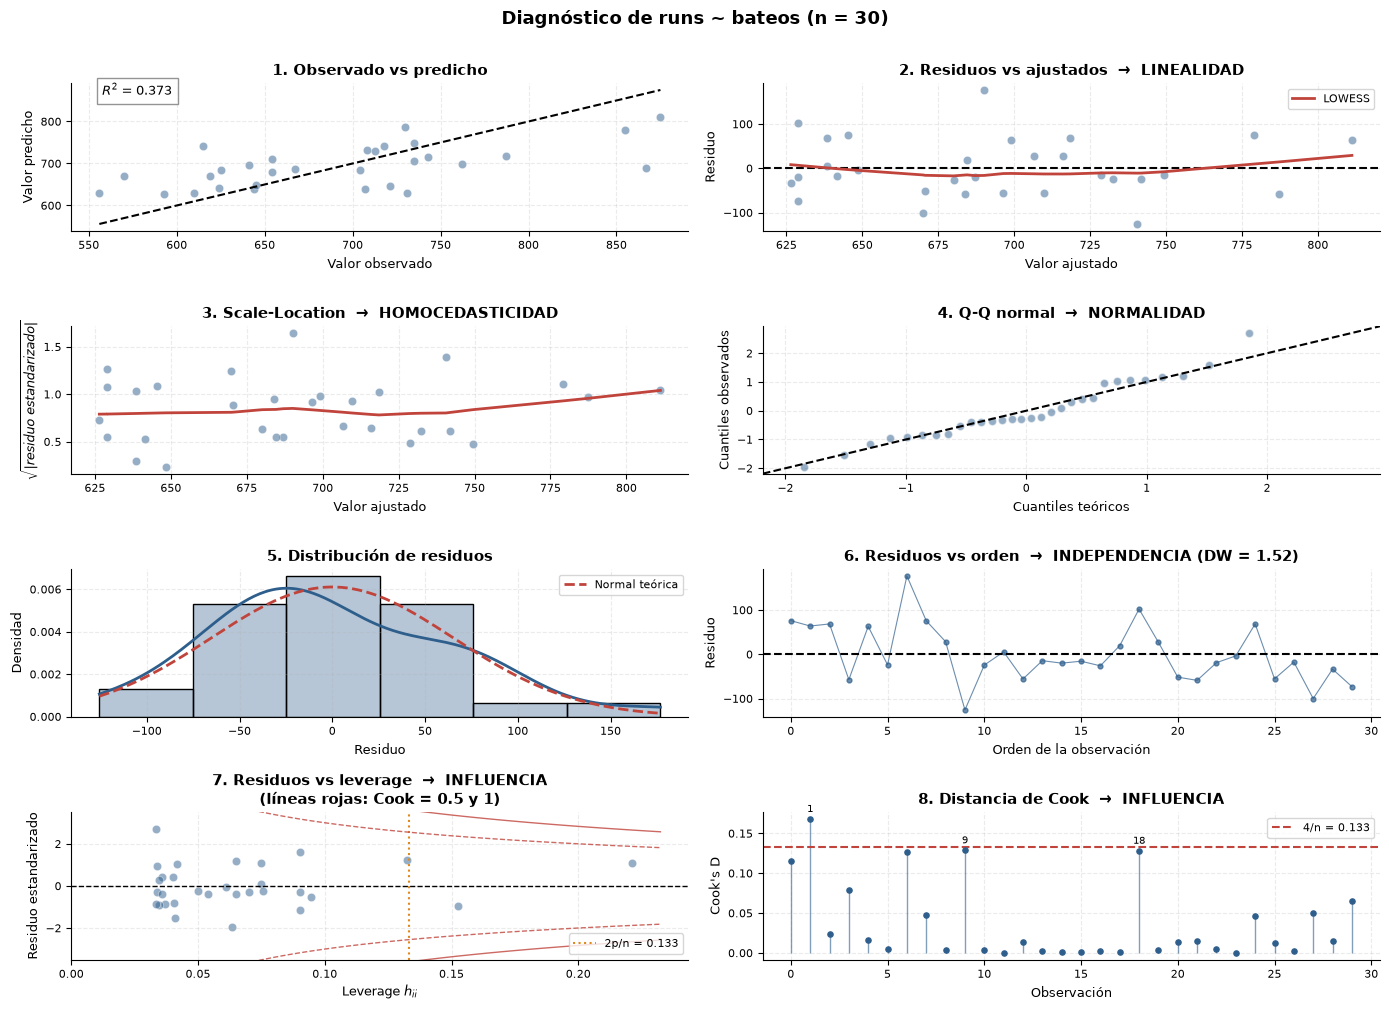

In [19]:
panel_diagnostico(modelo_simple, titulo='Diagnóstico de runs ~ bateos (n = 30)')

#### Lectura del panel

| Panel | Qué buscamos | Qué vemos |
|---|---|---|
| 1. Observado vs predicho | Puntos alineados en la diagonal | Dispersión amplia, coherente con $R^2 = 0.37$ |
| 2. Residuos vs ajustados | Nube sin estructura, LOWESS plana | LOWESS aproximadamente plana → **A1 se sostiene** |
| 3. Scale-Location | Línea horizontal | Sin tendencia clara → **A3 se sostiene** |
| 4. Q-Q plot | Puntos sobre la diagonal | Buen ajuste salvo un punto en la cola superior |
| 5. Histograma | Campana simétrica | Ligera asimetría positiva (skew = 0.54), aceptable |
| 6. Residuos vs orden | Sin rachas | **Ojo**: los datos están ordenados por runs, ver §2.8.5 |
| 7. Residuos vs leverage | Sin puntos fuera de los contornos de Cook | Ninguno cruza Cook = 0.5 |
| 8. Distancia de Cook | Sin picos dominantes | Un pico destacado (Boston) |

### 2.8.2 Chequeo mínimo priorizado

Los gráficos sugieren; los tests confirman. Ejecutamos **un test por supuesto**, indicando el
objetivo del análisis para que la función pueda priorizar: aquí queremos **interpretar los
coeficientes**, así que `objetivo='inferencia'`.

In [20]:
diagnostico(modelo_simple, objetivo='inferencia', orden_con_sentido=False)

OBJETIVO: INFERENCIA   ·   n = 30   ·   k = 1
VEREDICTO: ✅ PROCEDE — no hay violaciones relevantes para este objetivo.


Supuesto,Chequeo,Resultado,¿Se cumple?,Prioridad,Qué hacer
A1 · Linealidad,RESET de Ramsey,p = 0.501,✔,🟢 correcto,Seguir
A2 · Exogeneidad,NO hay test estadístico,requiere criterio del dominio,—,🟡 limita la lectura,Solo diseño experimental o variables instrumentales lo garantizan
A3 · Homocedasticidad,White,p = 0.951,✔,🟢 correcto,Seguir
A4 · Independencia,Durbin-Watson,DW = 1.52,—,⚪ no aplicable,Sin orden natural (tiempo/espacio) el test no es interpretable
A5 · Normalidad,Shapiro-Wilk,p = 0.337,✔,🟢 correcto,Seguir
Influencia,Cook's D,máx = 0.17 · 1 obs > 4/n,✔,🟢 correcto,Seguir


### 2.8.3 Normalidad de los residuos (A5)

El chequeo usa **Shapiro-Wilk** (el más potente con $n < 50$) y da $p = 0.34$: no se rechaza la
normalidad. Con $n = 30$ esto es una buena noticia, porque en muestras pequeñas la validez de los
tests $t$ y $F$ **sí** depende de A5 —el TLC todavía no nos rescata—. Si quisiéramos confirmarlo,
`diagnostico_completo()` añade Jarque-Bera ($p = 0.46$), D'Agostino ($p = 0.28$) y Anderson-Darling
($p = 0.18$): los cuatro coinciden.

🔍 Conviene saber qué mide cada uno para elegir bien, no para ejecutarlos todos:

| Test | Estadístico basado en | Fortaleza | Debilidad |
|---|---|---|---|
| **Shapiro-Wilk** | Correlación entre datos ordenados y cuantiles normales | El más potente en general con $n < 50$ | Muy sensible con $n$ grande: detecta desviaciones irrelevantes |
| **Jarque-Bera** | Asimetría y curtosis | Rápido, asintótico, muy usado en econometría | Poca potencia con $n$ pequeño |
| **D'Agostino-Pearson** (`Omnibus`) | Asimetría y curtosis, transformadas | El que trae el `summary()` | Requiere $n \gtrsim 20$ |
| **Anderson-Darling** | Distancia entre distribuciones empírica y teórica | **Pondera más las colas** | Menos conocido |

> **La paradoja del tamaño muestral.** Con $n = 10.000$, un test de normalidad rechazará $H_0$ ante
> desviaciones minúsculas y estadísticamente irrelevantes; con $n = 15$ no rechazará ni ante
> violaciones graves. Por eso el **Q-Q plot es más informativo que el p-valor**: muestra *dónde* y
> *cuánto* se desvía la distribución, no solo si la desviación es detectable.

### 2.8.4 Homocedasticidad (A3)

$$H_0: \text{Var}(\varepsilon_i \mid \mathbf X) = \sigma^2 \quad \text{para todo } i$$

El chequeo usa **White** ($p = 0.95$): no hay evidencia de heterocedasticidad. Existen tres tests
habituales y cada uno ataca el problema de forma distinta; esa diferencia será decisiva en el
Caso 2, así que conviene saber por qué usamos White por defecto:

- **Breusch-Pagan**: regresa $e_i^2$ sobre los predictores originales. Detecta heterocedasticidad
  que sea **función lineal** de los predictores. Estadístico $LM = n\cdot R^2_{aux} \sim \chi^2_k$.
- **White**: regresa $e_i^2$ sobre los predictores, **sus cuadrados y sus productos cruzados**.
  Es más general —detecta formas no lineales— a costa de perder potencia (consume muchos grados de
  libertad).
- **Goldfeld-Quandt**: ordena las observaciones, parte la muestra en dos y compara las varianzas
  residuales con un test $F$. Muy interpretable, pero requiere elegir bien la variable de orden.

> Adelanto: en el Caso 2 veremos Breusch-Pagan **no significativo** ($p = 0.195$) y White
> **fuertemente significativo** ($p = 2\times10^{-9}$) sobre el mismo modelo. La discrepancia no es
> un error: es información sobre la *forma* de la heterocedasticidad.

### 2.8.5 Linealidad y especificación funcional (A1)

El **RESET de Ramsey** (*Regression Equation Specification Error Test*) es el test formal más útil
que existe para detectar mala especificación, y el más ignorado. La idea es elegante:

1. Ajusta el modelo y obtén los valores ajustados $\hat y_i$.
2. Ajusta un modelo ampliado añadiendo potencias de $\hat y$: $\;y = \mathbf X\beta + \gamma_2\hat y^2 + \gamma_3 \hat y^3 + u$.
3. Contrasta $H_0: \gamma_2 = \gamma_3 = 0$ con un test $F$.

**Intuición:** si el modelo lineal capta bien la relación, ninguna transformación no lineal de sus
propias predicciones debería aportar información adicional. Si $\hat y^2$ resulta significativo, es
que falta curvatura, una interacción o una transformación.

Aquí RESET da $p = 0.50$: no hay evidencia de mala especificación. **A1 se sostiene.**

### 🔍 2.8.6 Ampliación · Independencia (A4) y la trampa de los tests que dependen del orden

El estadístico de Durbin-Watson vale 1.524, algo por debajo del 2 esperado bajo independencia:

$$DW = \frac{\sum_{i=2}^n (e_i - e_{i-1})^2}{\sum_{i=1}^n e_i^2} \approx 2(1-\hat\rho)$$

¿Debería preocuparnos? **No, y la razón es conceptualmente importante.**

DW —igual que Breusch-Godfrey o Harvey-Collier— mide correlación entre residuos **consecutivos
según el orden de las filas del DataFrame**. Ese orden solo tiene significado estadístico si
corresponde a algo real: tiempo, espacio, secuencia de medición. Estos 30 equipos están ordenados
aproximadamente por número de runs, que es un orden **arbitrario respecto al mecanismo generador**.

Vamos a demostrarlo empíricamente: si el "problema" fuese real, debería persistir al reordenar las
filas al azar. Si desaparece, era un artefacto del orden.

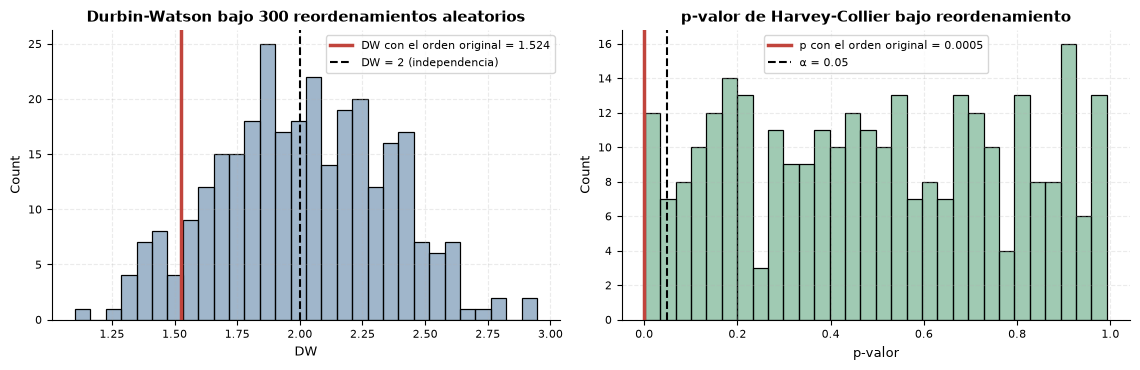

DW original: 1.524
DW tras permutar: media 2.012  ·  rango [1.10, 2.95]

Harvey-Collier con el orden original: p = 0.00053  → ¡significativo!
Harvey-Collier tras permutar: p mediano = 0.486  ·  % de permutaciones con p < 0.05: 5.3%


In [21]:
# ¿Es real la autocorrelación, o un artefacto del orden de las filas?
# ==============================================================================
from statsmodels.stats.diagnostic import linear_harvey_collier

dw_original = durbin_watson(modelo_simple.resid)
hc_original = linear_harvey_collier(modelo_simple)

dw_perm, hc_perm = [], []
for s in range(300):
    d_perm = beisbol.sample(len(beisbol), replace=False, random_state=s).reset_index(drop=True)
    m_perm = smf.ols('runs ~ bateos', data=d_perm).fit()
    dw_perm.append(durbin_watson(m_perm.resid))
    hc_perm.append(linear_harvey_collier(m_perm).pvalue)
dw_perm, hc_perm = np.array(dw_perm), np.array(hc_perm)

fig, ax = plt.subplots(1, 2, figsize=(11.5, 3.8))
sns.histplot(dw_perm, bins=30, color=AZUL, alpha=.45, ax=ax[0])
ax[0].axvline(dw_original, color=ROJO, lw=2.5, label=f'DW con el orden original = {dw_original:.3f}')
ax[0].axvline(2, color='black', ls='--', lw=1.5, label='DW = 2 (independencia)')
ax[0].legend(); ax[0].set(title='Durbin-Watson bajo 300 reordenamientos aleatorios', xlabel='DW')

sns.histplot(hc_perm, bins=30, color=VERDE, alpha=.45, ax=ax[1])
ax[1].axvline(hc_original.pvalue, color=ROJO, lw=2.5,
              label=f'p con el orden original = {hc_original.pvalue:.4f}')
ax[1].axvline(0.05, color='black', ls='--', lw=1.5, label='α = 0.05')
ax[1].legend(); ax[1].set(title='p-valor de Harvey-Collier bajo reordenamiento', xlabel='p-valor')
plt.tight_layout(); plt.show()

print(f"DW original: {dw_original:.3f}")
print(f"DW tras permutar: media {dw_perm.mean():.3f}  ·  rango [{dw_perm.min():.2f}, {dw_perm.max():.2f}]")
print(f"\nHarvey-Collier con el orden original: p = {hc_original.pvalue:.5f}  → ¡significativo!")
print(f"Harvey-Collier tras permutar: p mediano = {np.median(hc_perm):.3f}  ·  "
      f"% de permutaciones con p < 0.05: {100*(hc_perm < 0.05).mean():.1f}%")

#### Lectura de la trampa

Con el orden original, el test de **Harvey-Collier** da $p = 0.0005$: aparentemente, una violación
grave de la linealidad. Pero al reordenar las filas al azar, el p-valor mediano sube a ≈ 0.53 y
solo el ≈ 5% de las permutaciones resulta significativo —**exactamente la tasa de falsos positivos
nominal de un test bajo $H_0$ cierta**.

Conclusión: ese $p = 0.0005$ no detectaba ninguna propiedad del modelo, sino el hecho de que el
DataFrame venía ordenado por la variable respuesta. Lo mismo ocurre con DW: al permutar, se centra
en 2.02, justo el valor esperado bajo independencia.

> 🎯 **Regla:** los tests que dependen del orden de las observaciones (Durbin-Watson,
> Breusch-Godfrey, Harvey-Collier, CUSUM) **solo son interpretables si las filas tienen un orden
> con significado**. En datos transversales, reportar un DW es, en el mejor de los casos, ruido; en
> el peor, una conclusión inventada.

Por eso la función `tabla_diagnostico()` marca estos tests como *no aplicables* salvo que se
declare explícitamente `orden_con_sentido=True`. El diseño del análisis debe impedir el error, no
confiar en que el analista lo recuerde.

### 2.8.7 Outliers, leverage e influencia

Tres conceptos que suelen confundirse y que son **independientes entre sí**:

| Concepto | Definición | Se mide con | Umbral orientativo |
|---|---|---|---|
| **Outlier** | $y_i$ muy alejado de su predicción | Residuo estudentizado externo $t_i$ | $\vert t_i\vert > 3$, o test de Bonferroni |
| **Leverage** | $x_i$ muy alejado del centro de los predictores | $h_{ii}$ (diagonal de $\mathbf H$) | $h_{ii} > 2p/n$ |
| **Influencia** | Su eliminación **cambia el modelo** | Cook's $D$, DFFITS, DFBETAS | $D_i > 4/n$; $D_i > 1$ (grave) |

$$\text{Influencia} \;\approx\; \text{Outlier} \;\times\; \text{Leverage}$$

Una observación con residuo enorme pero leverage nulo (en el centro de la nube) apenas mueve la
recta. Una con leverage alto pero residuo nulo tampoco: confirma el ajuste, no lo distorsiona.
**El peligro es la combinación.** Anscombe III es el primer caso; Anscombe IV, el segundo.

Las métricas formales:

$$h_{ii} = \left[\mathbf X(\mathbf X^\top\mathbf X)^{-1}\mathbf X^\top\right]_{ii}, \qquad
\sum_i h_{ii} = p, \qquad \bar h = p/n$$

$$D_i = \frac{\sum_j (\hat y_j - \hat y_{j(i)})^2}{p\,\hat\sigma^2}
     = \frac{r_i^2}{p}\cdot\frac{h_{ii}}{1-h_{ii}}
\qquad\text{(Cook: efecto sobre TODAS las predicciones)}$$

$$\text{DFBETAS}_{j(i)} = \frac{\hat\beta_j - \hat\beta_{j(i)}}{SE(\hat\beta_{j(i)})}
\qquad\text{(efecto sobre UN coeficiente concreto)}$$

donde el subíndice $(i)$ indica "estimado sin la observación $i$".

In [22]:
# Tabla completa de influencia
# ==============================================================================
infl = modelo_simple.get_influence()
n_i, p_i = int(modelo_simple.nobs), int(modelo_simple.df_model) + 1

diag_infl = pd.DataFrame({
    'equipo'       : beisbol.equipos,
    'bateos'       : beisbol.bateos,
    'runs'         : beisbol.runs,
    'residuo'      : modelo_simple.resid,
    'resid_std'    : infl.resid_studentized_internal,
    'resid_stud'   : infl.resid_studentized_external,   # el correcto para detectar outliers
    'leverage'     : infl.hat_matrix_diag,
    'cook_D'       : infl.cooks_distance[0],
    'DFFITS'       : infl.dffits[0],
    'DFBETA_pend'  : infl.dfbetas[:, 1],
})

umbrales = {'leverage': 2 * p_i / n_i, 'cook_D': 4 / n_i,
            'DFFITS': 2 * np.sqrt(p_i / n_i), 'DFBETA_pend': 2 / np.sqrt(n_i)}
print("Umbrales de referencia:")
for k_, v_ in umbrales.items():
    print(f"   {k_:14s} > {v_:.4f}")

diag_infl['nº alertas'] = (
    (diag_infl.resid_stud.abs() > 3).astype(int)
    + (diag_infl.leverage > umbrales['leverage']).astype(int)
    + (diag_infl.cook_D > umbrales['cook_D']).astype(int)
    + (diag_infl.DFFITS.abs() > umbrales['DFFITS']).astype(int)
    + (diag_infl.DFBETA_pend.abs() > umbrales['DFBETA_pend']).astype(int)
)
display(diag_infl.sort_values('cook_D', ascending=False).head(8).style
        .format({'residuo': '{:.1f}', 'resid_std': '{:.2f}', 'resid_stud': '{:.2f}',
                 'leverage': '{:.3f}', 'cook_D': '{:.3f}', 'DFFITS': '{:.3f}',
                 'DFBETA_pend': '{:.3f}'})
        .background_gradient(subset=['cook_D'], cmap='Reds')
        .hide(axis='index'))

Umbrales de referencia:
   leverage       > 0.1333
   cook_D         > 0.1333
   DFFITS         > 0.5164
   DFBETA_pend    > 0.3651


equipo,bateos,runs,residuo,resid_std,resid_stud,leverage,cook_D,DFFITS,DFBETA_pend,nº alertas
Boston,5710,875,63.8,1.09,1.09,0.221,0.168,0.582,0.536,4
Houston,5598,615,-125.6,-1.95,-2.06,0.063,0.129,-0.536,-0.369,2
Arizona,5421,731,102.0,1.61,1.66,0.090,0.128,0.522,-0.414,2
New_Y.,5518,867,176.9,2.71,3.09,0.033,0.127,0.576,-0.040,2
Texas,5659,855,76.0,1.23,1.24,0.133,0.115,0.484,0.419,1
Kansas,5672,730,-57.2,-0.94,-0.93,0.153,0.079,-0.396,-0.350,1
Seattle,5421,556,-73.0,-1.15,-1.16,0.090,0.066,-0.364,0.289,0
San.F,5486,570,-100.0,-1.54,-1.58,0.041,0.050,-0.326,0.140,0


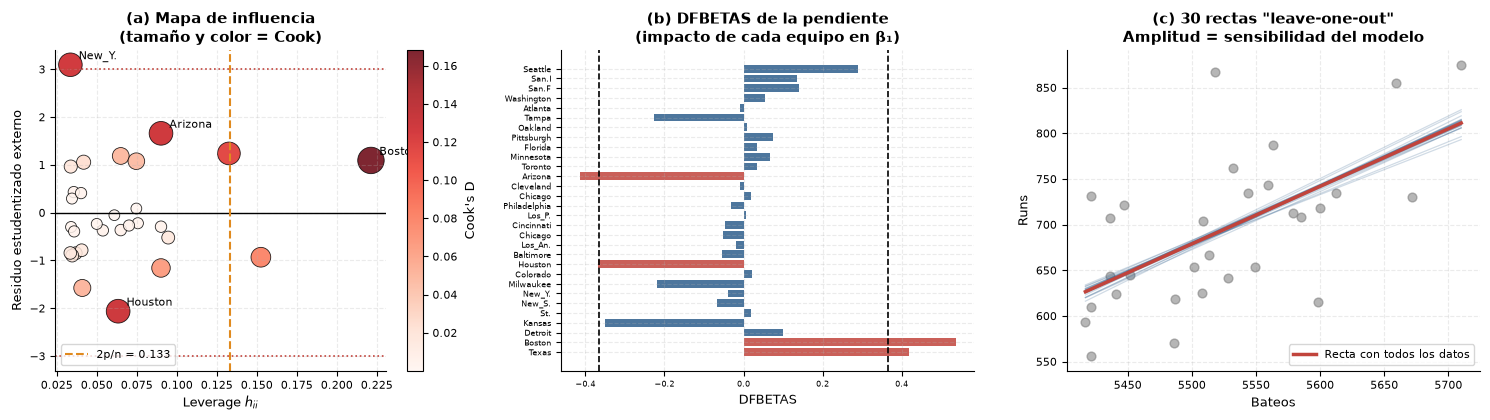

In [23]:
# Visualización: quién es outlier, quién es palanca, quién es influyente
# ==============================================================================
fig, axes = plt.subplots(1, 3, figsize=(15, 4.3))

# (a) mapa outlier vs leverage
sc = axes[0].scatter(diag_infl.leverage, diag_infl.resid_stud,
                     s=60 + 1800 * diag_infl.cook_D, c=diag_infl.cook_D,
                     cmap='Reds', edgecolors='black', lw=.6, alpha=.85)
axes[0].axhline(0, color='black', lw=1)
for umbral, estilo in [(3, ':'), (-3, ':')]:
    axes[0].axhline(umbral, color=ROJO, ls=estilo, lw=1.2)
axes[0].axvline(umbrales['leverage'], color=NARANJA, ls='--', lw=1.5,
                label=f"2p/n = {umbrales['leverage']:.3f}")
for _, fila in diag_infl.nlargest(4, 'cook_D').iterrows():
    axes[0].annotate(fila.equipo, (fila.leverage, fila.resid_stud),
                     textcoords='offset points', xytext=(6, 4), fontsize=8)
plt.colorbar(sc, ax=axes[0], label="Cook's D")
axes[0].legend(loc='lower left')
axes[0].set(title='(a) Mapa de influencia\n(tamaño y color = Cook)',
            xlabel='Leverage $h_{ii}$', ylabel='Residuo estudentizado externo')

# (b) DFBETAS de la pendiente
colores = [ROJO if abs(v) > umbrales['DFBETA_pend'] else AZUL for v in diag_infl.DFBETA_pend]
y_pos = np.arange(len(diag_infl))
axes[1].barh(y_pos, diag_infl.DFBETA_pend, color=colores, alpha=.85)
axes[1].set_yticks(y_pos, diag_infl.equipo)
for signo in (1, -1):
    axes[1].axvline(signo * umbrales['DFBETA_pend'], color='black', ls='--', lw=1.2)
axes[1].tick_params(labelsize=6)
axes[1].set(title='(b) DFBETAS de la pendiente\n(impacto de cada equipo en β₁)', xlabel='DFBETAS')

# (c) efecto de eliminar cada observación sobre la recta
axes[2].scatter(beisbol.bateos, beisbol.runs, s=40, color=GRIS, alpha=.55, zorder=2)
xg = np.linspace(beisbol.bateos.min(), beisbol.bateos.max(), 20)
for i in range(len(beisbol)):
    m_i = smf.ols('runs ~ bateos', data=beisbol.drop(index=i)).fit()
    axes[2].plot(xg, m_i.params['Intercept'] + m_i.params['bateos'] * xg,
                 color=AZUL, alpha=.22, lw=.9)
axes[2].plot(xg, modelo_simple.params['Intercept'] + modelo_simple.params['bateos'] * xg,
             color=ROJO, lw=2.5, label='Recta con todos los datos', zorder=3)
axes[2].legend()
axes[2].set(title='(c) 30 rectas "leave-one-out"\nAmplitud = sensibilidad del modelo',
            xlabel='Bateos', ylabel='Runs')
plt.tight_layout(); plt.show()

In [24]:
# Test formal de outliers con corrección por comparaciones múltiples
# ==============================================================================
test_outliers = modelo_simple.outlier_test(method='bonf')
test_outliers.insert(0, 'equipo', beisbol.equipos.values)
print("Test de outliers (residuo estudentizado externo, ajuste de Bonferroni):")
display(test_outliers.sort_values('unadj_p').head(5).round(4))

print('''
Interpretación:
  · New_Y. tiene un residuo estudentizado de 3.09 y un p-valor SIN AJUSTAR de 0.0046.
    Aislado, parecería un outlier claro.
  · Pero estamos haciendo 30 contrastes simultáneos (uno por observación). Bajo H0,
    esperaríamos 30 x 0.05 = 1.5 falsos positivos solo por azar.
  · Tras la corrección de Bonferroni (p x 30), el p-valor sube a 0.137: NO hay
    evidencia de que ninguna observación sea un outlier genuino.
''')

Test de outliers (residuo estudentizado externo, ajuste de Bonferroni):


,equipo,student_resid,unadj_p,bonf(p)
6,New_Y.,3.0929,0.0046,0.1371
9,Houston,-2.0622,0.0489,1.0000
18,Arizona,1.6587,0.1087,1.0000
27,San.F,-1.5756,0.1268,1.0000
0,Texas,1.2386,0.2262,1.0000



Interpretación:
  · New_Y. tiene un residuo estudentizado de 3.09 y un p-valor SIN AJUSTAR de 0.0046.
    Aislado, parecería un outlier claro.
  · Pero estamos haciendo 30 contrastes simultáneos (uno por observación). Bajo H0,
    esperaríamos 30 x 0.05 = 1.5 falsos positivos solo por azar.
  · Tras la corrección de Bonferroni (p x 30), el p-valor sube a 0.137: NO hay
    evidencia de que ninguna observación sea un outlier genuino.



In [25]:
# ¿Cambian las conclusiones si eliminamos las observaciones más influyentes?
# ==============================================================================
candidatos = diag_infl.nlargest(3, 'cook_D').equipo.tolist()
filas = [{'escenario': 'Modelo completo (n=30)', 'n': int(modelo_simple.nobs),
          'pendiente': modelo_simple.params['bateos'], 'SE': modelo_simple.bse['bateos'],
          'IC inf': modelo_simple.conf_int().loc['bateos', 0],
          'IC sup': modelo_simple.conf_int().loc['bateos', 1],
          'R²': modelo_simple.rsquared, 'p-valor': modelo_simple.pvalues['bateos']}]

for eq in candidatos:
    d_sin = beisbol[beisbol.equipos != eq]
    m_sin = smf.ols('runs ~ bateos', data=d_sin).fit()
    filas.append({'escenario': f'Sin {eq}', 'n': int(m_sin.nobs),
                  'pendiente': m_sin.params['bateos'], 'SE': m_sin.bse['bateos'],
                  'IC inf': m_sin.conf_int().loc['bateos', 0],
                  'IC sup': m_sin.conf_int().loc['bateos', 1],
                  'R²': m_sin.rsquared, 'p-valor': m_sin.pvalues['bateos']})

sens = pd.DataFrame(filas)
sens['Δ pendiente %'] = 100 * (sens.pendiente - sens.pendiente.iloc[0]) / sens.pendiente.iloc[0]
display(sens.style.format({'pendiente': '{:.4f}', 'SE': '{:.4f}', 'IC inf': '{:.3f}',
                           'IC sup': '{:.3f}', 'R²': '{:.3f}', 'p-valor': '{:.5f}',
                           'Δ pendiente %': '{:+.1f}%'}).hide(axis='index'))

escenario,n,pendiente,SE,IC inf,IC sup,R²,p-valor,Δ pendiente %
Modelo completo (n=30),30,0.6305,0.1545,0.314,0.947,0.373,0.00034,+0.0%
Sin Boston,29,0.5480,0.1716,0.196,0.900,0.274,0.00356,-13.1%
Sin Houston,29,0.6845,0.1486,0.380,0.989,0.440,0.00009,+8.6%
Sin Arizona,29,0.6927,0.1545,0.376,1.010,0.427,0.00012,+9.9%


#### Conclusión del análisis de influencia

- **Ninguna observación supera $D_i = 0.5$**, el umbral habitual de preocupación seria. El máximo
  es Boston con $D = 0.168$.
- El test de outliers con corrección de Bonferroni **no identifica ningún outlier genuino**.
- Sin embargo, el **análisis de sensibilidad** revela algo que las métricas por sí solas no gritan:
  eliminar Boston reduce la pendiente un **−13%** (de 0.631 a 0.548) y el $R^2$ de 0.373 a 0.274.
  Boston tiene el leverage más alto ($h = 0.221$, más de 3 veces la media $p/n = 0.067$) porque es
  el equipo que más batea de toda la muestra.

> **Criterio profesional:** una observación influyente **no se elimina** por ser influyente. Se
> elimina únicamente si hay razones sustantivas (error de medición, unidad que no pertenece a la
> población de interés). Boston es un equipo perfectamente legítimo. Lo correcto es **reportar la
> sensibilidad**: "los resultados dependen apreciablemente de un único equipo", que es una
> conclusión honesta y valiosa sobre la fragilidad del modelo con $n = 30$.

---

## 2.9 Validación predictiva honesta

El modelo ha superado el diagnóstico: los supuestos se sostienen razonablemente. Pero **un modelo
válido no es necesariamente un modelo útil.** Ahora medimos su capacidad predictiva real.

### 2.9.1 El problema del train/test con muestras pequeñas

El notebook original partía los 30 equipos en 24/6 y reportaba un RMSE de test de 59.34 como si
fuera *el* error del modelo. Con 6 observaciones de test, ese número es prácticamente ruido.
Cuantifiquémoslo: repetimos la misma partición 80/20 con 500 semillas distintas.

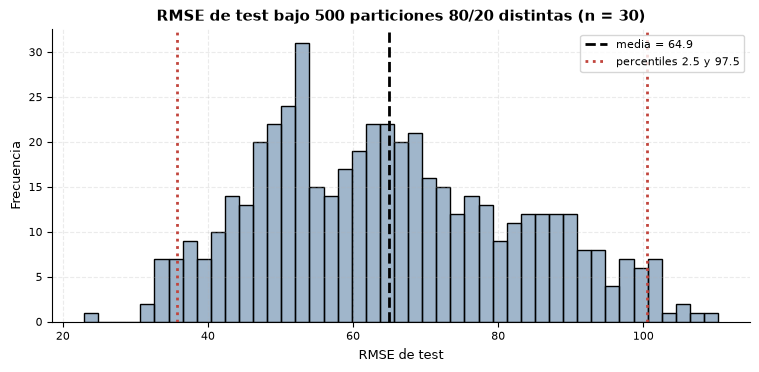

RMSE de test:  media 64.89  ·  desv. típica 17.61
Rango observado: [22.91, 110.30]
IC empírico 95%: [35.76, 100.47]

El mismo modelo, sobre los mismos datos, puede 'demostrar' un RMSE de 23 o de 110 según qué semilla se elija.


In [26]:
# ¿Cuánto depende el "RMSE de test" de la partición concreta?
# ==============================================================================
X_np, y_np = beisbol[['bateos']].values, beisbol['runs'].values
rmse_particiones = []
for semilla in range(500):
    X_tr, X_te, y_tr, y_te = train_test_split(X_np, y_np, train_size=0.8,
                                              random_state=semilla, shuffle=True)
    m_tmp = sm.OLS(y_tr, sm.add_constant(X_tr)).fit()
    pred_tmp = m_tmp.predict(sm.add_constant(X_te))
    rmse_particiones.append(np.sqrt(np.mean((y_te - pred_tmp) ** 2)))
rmse_particiones = np.array(rmse_particiones)

fig, ax = plt.subplots(figsize=(9, 3.8))
sns.histplot(rmse_particiones, bins=45, color=AZUL, alpha=.45, ax=ax)
ax.axvline(rmse_particiones.mean(), color='black', ls='--', lw=2,
           label=f'media = {rmse_particiones.mean():.1f}')
ax.axvline(np.percentile(rmse_particiones, 2.5), color=ROJO, ls=':', lw=2, label='percentiles 2.5 y 97.5')
ax.axvline(np.percentile(rmse_particiones, 97.5), color=ROJO, ls=':', lw=2)
ax.legend()
ax.set(title='RMSE de test bajo 500 particiones 80/20 distintas (n = 30)',
       xlabel='RMSE de test', ylabel='Frecuencia')
plt.show()

print(f"RMSE de test:  media {rmse_particiones.mean():.2f}  ·  desv. típica {rmse_particiones.std():.2f}")
print(f"Rango observado: [{rmse_particiones.min():.2f}, {rmse_particiones.max():.2f}]")
print(f"IC empírico 95%: [{np.percentile(rmse_particiones, 2.5):.2f}, "
      f"{np.percentile(rmse_particiones, 97.5):.2f}]")
print(f"\nEl mismo modelo, sobre los mismos datos, puede 'demostrar' un RMSE de "
      f"{rmse_particiones.min():.0f} o de {rmse_particiones.max():.0f} según qué semilla se elija.")

> ⚠️ **Esto es un vector de p-hacking real y frecuente.** Si alguien prueba varias semillas y
> reporta la que da mejor resultado, obtiene un número técnicamente cierto y completamente
> engañoso. Con $n$ pequeño, **una única partición train/test no es una estimación del error de
> generalización**: es una realización de una variable aleatoria con una desviación típica enorme.

### 2.9.2 La alternativa: validación cruzada y PRESS

Con muestras pequeñas, la estrategia correcta es la **validación cruzada**, que usa todas las
observaciones tanto para entrenar como para validar (en distintas iteraciones):

- **K-fold**: se divide en $K$ bloques; se entrena con $K-1$ y se valida con el restante, rotando.
- **LOOCV** ($K = n$): el caso extremo. En regresión lineal tiene una propiedad notable: **se puede
  calcular exactamente sin reajustar el modelo ni una sola vez**, gracias al leverage:

$$e_{(i)} = \frac{e_i}{1-h_{ii}} \qquad\Longrightarrow\qquad
\text{PRESS} = \sum_{i=1}^n \left(\frac{e_i}{1-h_{ii}}\right)^2$$

donde $e_{(i)}$ es el error al predecir la observación $i$ con un modelo ajustado **sin ella**.
De ahí se define el $R^2$ **predictivo**:

$$R^2_{\text{pred}} = 1 - \frac{\text{PRESS}}{SST}$$

que, a diferencia del $R^2$ habitual, **sí puede bajar** al añadir variables inútiles y es mucho
más honesto sobre la capacidad de generalización.

In [27]:
# Validación cruzada: K-fold repetido y LOOCV analítico
# ==============================================================================
def cv_rmse(formula, data, y_col, k=5, repeticiones=20):
    '''RMSE por validación cruzada K-fold repetida sobre un modelo de fórmula.'''
    errores = []
    for rep in range(repeticiones):
        kf = KFold(n_splits=k, shuffle=True, random_state=rep)
        for i_tr, i_te in kf.split(data):
            m = smf.ols(formula, data=data.iloc[i_tr]).fit()
            pred = m.predict(data.iloc[i_te])
            errores.append(np.mean((data.iloc[i_te][y_col] - pred) ** 2))
    return np.sqrt(np.mean(errores)), np.sqrt(np.array(errores)).std()

rmse_cv, sd_cv = cv_rmse('runs ~ bateos', beisbol, 'runs', k=5, repeticiones=20)

h_ii  = modelo_simple.get_influence().hat_matrix_diag
press = np.sum((modelo_simple.resid / (1 - h_ii)) ** 2)
sst   = modelo_simple.centered_tss
rmse_loocv = np.sqrt(press / len(beisbol))
r2_pred    = 1 - press / sst

# Modelo nulo de referencia: predecir siempre la media
rmse_nulo = beisbol.runs.std(ddof=1)

comparativa = pd.DataFrame({
    'Métrica': ['RMSE en entrenamiento (optimista)',
                'RMSE 5-fold CV × 20 repeticiones',
                'RMSE LOOCV (vía PRESS)',
                'RMSE del modelo NULO (predecir la media)'],
    'Valor'  : [np.sqrt(modelo_simple.mse_resid), rmse_cv, rmse_loocv, rmse_nulo],
})
comparativa['vs modelo nulo'] = 100 * (comparativa.Valor / rmse_nulo - 1)
display(comparativa.style.format({'Valor': '{:.2f}', 'vs modelo nulo': '{:+.1f}%'}).hide(axis='index'))

print(f"\nR²           (ajuste, en muestra)      = {modelo_simple.rsquared:.4f}")
print(f"R² ajustado                            = {modelo_simple.rsquared_adj:.4f}")
print(f"R² PREDICTIVO (1 - PRESS/SST, LOOCV)   = {r2_pred:.4f}")
print(f"\nOptimismo del ajuste: {modelo_simple.rsquared - r2_pred:.4f} "
      f"({100*(modelo_simple.rsquared - r2_pred)/modelo_simple.rsquared:.0f}% del R² es sobreajuste)")

Métrica,Valor,vs modelo nulo
RMSE en entrenamiento (optimista),66.47,-19.4%
RMSE 5-fold CV × 20 repeticiones,70.07,-15.0%
RMSE LOOCV (vía PRESS),68.84,-16.5%
RMSE del modelo NULO (predecir la media),82.48,+0.0%



R²           (ajuste, en muestra)      = 0.3729
R² ajustado                            = 0.3505
R² PREDICTIVO (1 - PRESS/SST, LOOCV)   = 0.2793

Optimismo del ajuste: 0.0935 (25% del R² es sobreajuste)


### 2.9.3 Veredicto predictivo

| Métrica | Valor | Lectura |
|---|---|---|
| $R^2$ en muestra | 0.373 | Lo que el modelo *parece* explicar |
| $R^2$ predictivo | 0.279 | Lo que realmente explicaría en equipos nuevos |
| RMSE LOOCV | ≈ 69 runs | Error esperado en predicción |
| RMSE del modelo nulo | ≈ 82 runs | Error de predecir siempre la media |

El modelo reduce el error de predicción **solo alrededor de un 16%** respecto a no usar modelo
alguno. Y un cuarto del $R^2$ aparente es sobreajuste.

> **Síntesis del caso 1:**
> **Estadísticamente válido ≠ prácticamente útil.**
> La relación entre bateos y runs es real y significativa ($p = 0.0003$), el modelo cumple los
> supuestos y la inferencia es legítima. Pero la capacidad predictiva es modesta: el intervalo de
> predicción para un equipo concreto cubre ≈ 260 runs, y el error esperado apenas mejora al de
> predecir la media.
>
> Responder a la pregunta del analista deportivo —"¿puedo predecir el resultado del partido?"—
> exige mirar el **intervalo de predicción** y el **$R^2$ predictivo**, no el p-valor. Un análisis
> que se quedara en "r = 0.61, p < 0.001, existe relación significativa" habría dado una respuesta
> formalmente correcta y prácticamente equivocada.

## 2.10 Ficha resumen del caso

### 🚦 Decisión sobre el caso

El diagnóstico da luz verde: ningún supuesto relevante falla. Pero **validar los supuestos no es
validar la utilidad**. Aplicando la Regla 1 (el objetivo manda), la respuesta depende de para qué
se quiera el modelo:

| Objetivo del analista deportivo | ¿Sirve este modelo? | Por qué |
|---|---|---|
| Cuantificar la asociación bateos–runs | ✅ **Sí** | Supuestos cumplidos, inferencia válida: $\beta_1 \in [0.31,\ 0.95]$ |
| Predecir las runs de **un equipo concreto** | ❌ **No** | El intervalo de predicción cubre ±138 runs |
| Afirmar que batear más **causa** más runs | ❌ **No** | Estudio observacional: A2 no es contrastable |

> **Este es el caso que ilustra la Regla 4:** a veces el resultado profesional correcto es *"con
> estos datos no se puede responder a esa pregunta"*. Y esa conclusión solo aparece si se miran el
> intervalo de predicción y el $R^2$ predictivo — nunca aparece mirando el p-valor.

**Si hubiera que mejorar la predicción**, el orden de prioridad sería: (1) añadir predictores
relevantes —los bateos explican solo el 37% de la varianza—, (2) aumentar $n$, y (3) solo entonces
probar formas funcionales más complejas. Refinar la técnica sobre datos insuficientes es el error
más caro de todos.

In [28]:
# Ficha final del modelo simple
# ==============================================================================
ficha = resumen_modelo(modelo_simple, 'runs ~ bateos')
display(ficha.to_frame('valor').style.format({'valor': lambda v: f'{v:,.4f}' if isinstance(v, float) else v}))

print(f'''
ECUACIÓN AJUSTADA
    runs = {modelo_simple.params['Intercept']:.2f} + {modelo_simple.params['bateos']:.4f} × bateos
    (válida solo para bateos ∈ [{beisbol.bateos.min()}, {beisbol.bateos.max()}])

INFERENCIA
    β₁ = {modelo_simple.params['bateos']:.4f}   IC95% = [{modelo_simple.conf_int().loc['bateos',0]:.3f}, {modelo_simple.conf_int().loc['bateos',1]:.3f}]   p = {modelo_simple.pvalues['bateos']:.5f}

SUPUESTOS
    A1 Linealidad       ✔  RESET p = 0.50, LOWESS plana
    A3 Homocedasticidad ✔  Breusch-Pagan p = 0.91, White p = 0.95
    A5 Normalidad       ✔  Shapiro p = 0.34, Jarque-Bera p = 0.46
    A4 Independencia    –  no evaluable (beisbol transversales sin orden natural)
    Influencia          ⚠  Boston: leverage alto; su exclusión cambia β₁ un -13%

CAPACIDAD PREDICTIVA
    R² predictivo = {r2_pred:.3f}   ·   RMSE LOOCV = {rmse_loocv:.1f} runs   ·   modelo nulo = {rmse_nulo:.1f} runs
    → Mejora sobre no modelar: {100*(1 - rmse_loocv/rmse_nulo):.0f}%
''')

,valor
modelo,runs ~ bateos
n,30
k (predictores),1
R²,0.3729
R² ajustado,0.3505
R² predictivo,0.2793
F,16.6475
p(F),0.0003
AIC,338.8741
BIC,341.6765



ECUACIÓN AJUSTADA
    runs = -2789.24 + 0.6305 × bateos
    (válida solo para bateos ∈ [5417, 5710])

INFERENCIA
    β₁ = 0.6305   IC95% = [0.314, 0.947]   p = 0.00034

SUPUESTOS
    A1 Linealidad       ✔  RESET p = 0.50, LOWESS plana
    A3 Homocedasticidad ✔  Breusch-Pagan p = 0.91, White p = 0.95
    A5 Normalidad       ✔  Shapiro p = 0.34, Jarque-Bera p = 0.46
    A4 Independencia    –  no evaluable (beisbol transversales sin orden natural)
    Influencia          ⚠  Boston: leverage alto; su exclusión cambia β₁ un -13%

CAPACIDAD PREDICTIVA
    R² predictivo = 0.279   ·   RMSE LOOCV = 68.8 runs   ·   modelo nulo = 82.5 runs
    → Mejora sobre no modelar: 17%



---

## Cierre del notebook 01

**Lo que llevamos:**

- Un **protocolo de 6 pasos** que aplicaremos a todos los modelos del módulo.
- Un **marco de prioridades** (🔴 / 🟡 / 🟢) para decidir qué hacer cuando un supuesto falla.
- La distinción entre **modelo válido** y **modelo útil**: este caso es lo primero y no lo segundo.

**Lo que queda abierto:**

Con un solo predictor, el diagnóstico salió limpio y el problema fue de *potencia*: los bateos
simplemente no contienen suficiente información sobre las carreras.

Pero en la práctica casi nunca hay un solo predictor. Y en cuanto hay varios aparecen fenómenos
que aquí no podían darse:

- un predictor puede parecer relevante **solo porque otro lo está empujando** (confusión),
- los predictores pueden **potenciarse entre sí** (interacción),
- la relación puede **saturarse** en vez de ser una recta,
- y varios supuestos pueden fallar **a la vez**, con una única causa detrás.

Eso es exactamente lo que veremos en el **notebook 02**, con un caso de negocio real: decidir en
qué canales de publicidad invertir. Allí el diagnóstico no será un trámite: será lo que multiplique
por cuatro la calidad del modelo.